# for picking best health_score and terminal models
## based on amount of advantage accumulated and how in-distribution the policy is

## the formula is: 
One thing worth flagging for the paper's methods section, since you're now using three sequential criteria: state the full selection cascade explicitly and in this order — (1) exclude own-critic advantage ≤ 0 [training-validity gate], (2) exclude alphas at/above the SARSA-advantage instability onset [reliability gate], (3) among survivors, select by highest occupancy support, breaking ties by SARSA-advantage [safety-first final pick]. That's a fully principled, three-stage, pre-specified procedure — worth writing it as a single clear paragraph or even a small flowchart/algorithm box, since a reviewer will want to see this reasoning laid out plainly rather than reconstructed from separate analyses.

In [23]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.action_distribution_sweep as action_dist
import src.rl.clinician_baseline as clin_baseline
import src.rl.reward_by_vaso_match as vaso_match
import src.rl.dose_histogram_by_alpha as dose_hist
import src.rl.inspect_fluid_params as raw_params
import src.rl.check_std_floor as std_check
import src.rl.diagnose_fluid_spike as spike_diag
import src.rl.plot_fluid_two_population as fluid_pop
import src.rl.plot_fluid_dose_severity_heatmaps as heatmap_diag
import src.rl.final_model_selection as final_select

# SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/cql_alpha_sweep"
# os.makedirs(SAVE_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# get paths to the models

In [2]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")

    elif health_cohort == "sepsis_picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")


Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset


# get state dim from the dynamic deephit model

In [3]:
# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension from dynamic deephit hyperparameters: 128


# Load SARSA models x 5 seeds

In [4]:
basic_q_terminal_model_dir = os.path.join(basic_q_dir, "terminal_only")
basic_q_terminal_model_dirs = eval_cql.get_model_dirs(basic_q_terminal_model_dir)

basic_q_terminal_models = []
for model_dir in basic_q_terminal_model_dirs:
    # load terminal sarsa model
    terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='terminal', model_dir=model_dir, state_dim=state_dim)
    basic_q_terminal_models.append((terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-163424_71f56fa6
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-165417_d7c6986a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-171719_bd2e5ef8
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_fr

In [5]:
basic_q_health_score_model_dir = os.path.join(basic_q_dir, "health_score_change_only")
basic_q_health_score_model_dirs = etm.get_model_dirs(basic_q_health_score_model_dir)

basic_q_health_score_models = []
for model_dir in basic_q_health_score_model_dirs:
    # load health score sarsa model
    health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-172402_1ce5be77
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-165737_72aa451a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-174709_9876cf65
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-

# Load CQL models

In [6]:
cql_terminal_model_dir = os.path.join(cql_model_dir, "terminal_only", "cql_alpha_sweep")
cql_terminal_model_dirs = eval_cql.get_model_dirs(cql_terminal_model_dir)

cql_terminal_models = []
for model_dir in cql_terminal_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260911_223745/unknown_cx3-20-0_20260911-223912_0c6ceeee
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260911_223745/unknown_cx3-20-0_20260912-002919_a3a627ea
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260911_223745/unknown_cx3-20-0_20260911-234429_a1242557
Found model directory: /home/jake/Documents/AI

In [7]:
cql_health_score_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "cql_alpha_sweep")
cql_health_score_model_dirs = eval_cql.get_model_dirs(cql_health_score_model_dir)

cql_health_score_models = []
for model_dir in cql_health_score_model_dirs:
    # load health score model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260912_123321/unknown_cx3-20-3_20260912-133953_81adcdb0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260912_123321/unknown_cx3-20-3_20260912-123448_82624754
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260912_123321/unknown_cx3-20-3_20260912-131804_1b6233bc
Found model d

# Load data

In [8]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

In [9]:
processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [10]:
# real clinician non-zero fluid doses, from training data
fluid_doses = processors['train'].rl_dataset["actions"][:, 0]
nonzero_fluid = fluid_doses[fluid_doses > 1e-4]

# clamp to avoid inf at exact 0/1 boundaries, then invert the sigmoid (logit)
nonzero_fluid_clamped = nonzero_fluid.clamp(1e-4, 1 - 1e-4)
raw_fluid = torch.logit(nonzero_fluid_clamped)

print(f"Fluid: dose-space std={nonzero_fluid.std():.4f}, "
      f"raw-space std={raw_fluid.std():.4f}, raw-space mean={raw_fluid.mean():.4f}")

# same for vaso
vaso_doses = processors['train'].rl_dataset["actions"][:, 1]
nonzero_vaso = vaso_doses[vaso_doses > 1e-4]
nonzero_vaso_clamped = nonzero_vaso.clamp(1e-4, 1 - 1e-4)
raw_vaso = torch.logit(nonzero_vaso_clamped)

print(f"Vaso: dose-space std={nonzero_vaso.std():.4f}, "
      f"raw-space std={raw_vaso.std():.4f}, raw-space mean={raw_vaso.mean():.4f}")

Fluid: dose-space std=0.1420, raw-space std=0.6721, raw-space mean=0.1841
Vaso: dose-space std=0.1158, raw-space std=0.6342, raw-space mean=-1.0675


In [11]:
actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615


# clinician baseline

In [12]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569


In [13]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


## health_score

In [14]:
training_health_score = processors['train'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
training_health_score = np.delete(training_health_score, indices_to_remove)

val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

training_actions = processors['train'].rl_dataset["actions"]

# Calculate advantage at all cql alpha values

## health score models

In [15]:
# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_models}
cql_terminal_by_alpha = {m[3]['cql_alpha']: m for m in cql_terminal_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))
print("Terminal alphas found:", sorted(cql_terminal_by_alpha.keys()))

Health-score alphas found: [0.0, 0.0001, 0.001, 0.005, 0.01, 0.015, 0.016, 0.017, 0.018, 0.019, 0.02, 0.021, 0.022, 0.023, 0.024, 0.025, 0.026, 0.027, 0.028, 0.029, 0.03, 0.035, 0.04, 0.045, 0.05, 0.075, 0.1, 0.5, 1.0]
Terminal alphas found: [0.0, 0.0001, 0.001, 0.005, 0.01, 0.015, 0.016, 0.017, 0.018, 0.019, 0.02, 0.021, 0.022, 0.023, 0.024, 0.025, 0.026, 0.027, 0.028, 0.029, 0.03, 0.035, 0.04, 0.045, 0.05, 0.075, 0.1, 0.5, 1.0]


=== alpha=0.0 (deterministic eval) ===


    own-critic Q IQR (real clinician actions): 0.9842
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  own-critic advantage:   raw=0.0375, normalized=0.0381
  SARSA-critic advantage: raw mean=0.0790, normalized mean=0.0801 (normalized per-seed=[0.0809 0.0814 0.0816 0.0797 0.0768])
  occupancy support of chosen actions: 85.2%
  done in 6.2s

=== alpha=0.0001 (deterministic eval) ===
    own-critic Q IQR (real clinician actions): 1.0276
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  own-critic advantage:   raw=0.0393, normalized

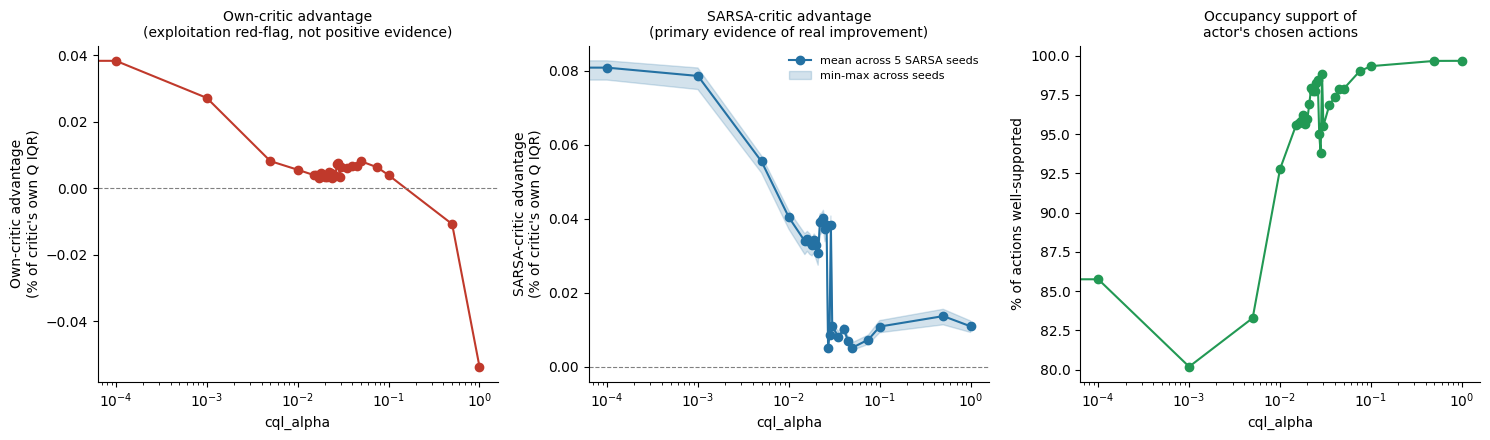

In [32]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_health_score_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_health_score, fig_health_score = eval_cql.run_alpha_sweep_analysis(
    cql_health_score_by_alpha,
    processors['val'],
    basic_q_health_score_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 200,
    save_path=save_path,
)

Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_health_score_n_severity_bins_100.png


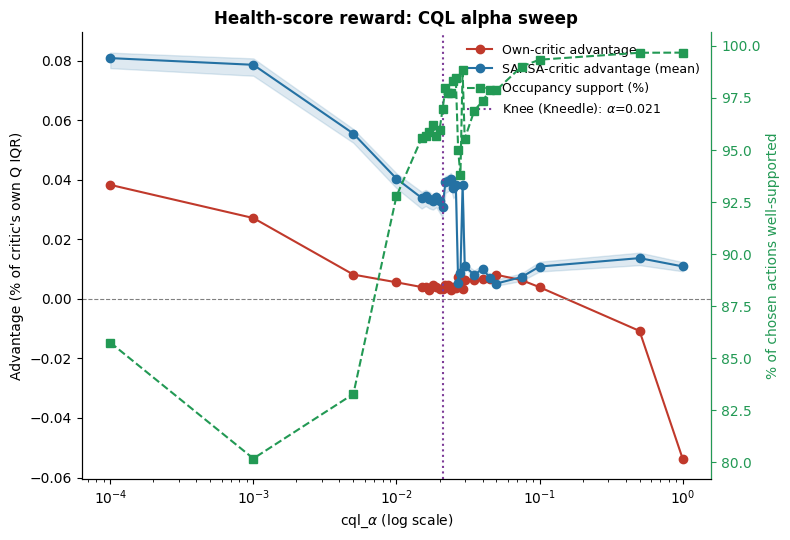

In [33]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_health_score_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_health_score,
    normalized=True, log_scale=True,
    title="Health-score reward: CQL alpha sweep",
    save_path=save_path,
)

## terminal models

=== alpha=0.0 (deterministic eval) ===


    own-critic Q IQR (real clinician actions): 3.4619
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2742, normalized=0.0792
  SARSA-critic advantage: raw mean=0.2790, normalized mean=0.0807 (normalized per-seed=[0.0826 0.0928 0.0697 0.0848 0.0735])
  occupancy support of chosen actions: 80.4%
  done in 6.2s

=== alpha=0.0001 (deterministic eval) ===
    own-critic Q IQR (real clinician actions): 3.4612
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2695, normalized

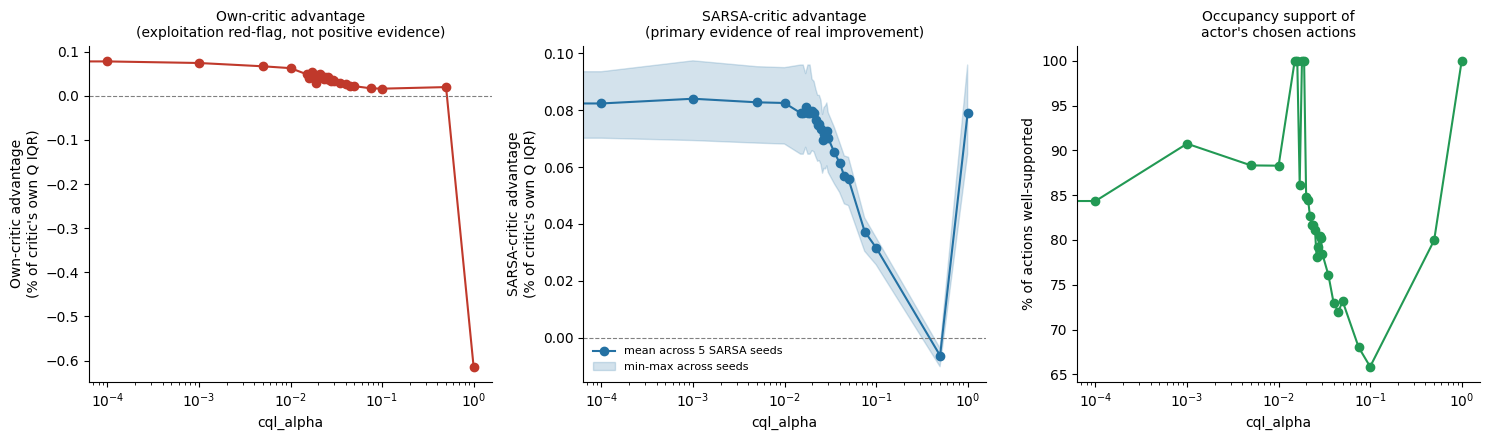

In [34]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_terminal_n_severity_bins_100.png")    


# --- Terminal reward: CQL alpha sweep vs. all 5 terminal SARSA seeds ---
results_terminal, fig_terminal = eval_cql.run_alpha_sweep_analysis(
    cql_terminal_by_alpha,
    processors['val'],
    basic_q_terminal_models,   # the 5 terminal SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 200,
    save_path=save_path,
)

Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_terminal_n_severity_bins_100.png


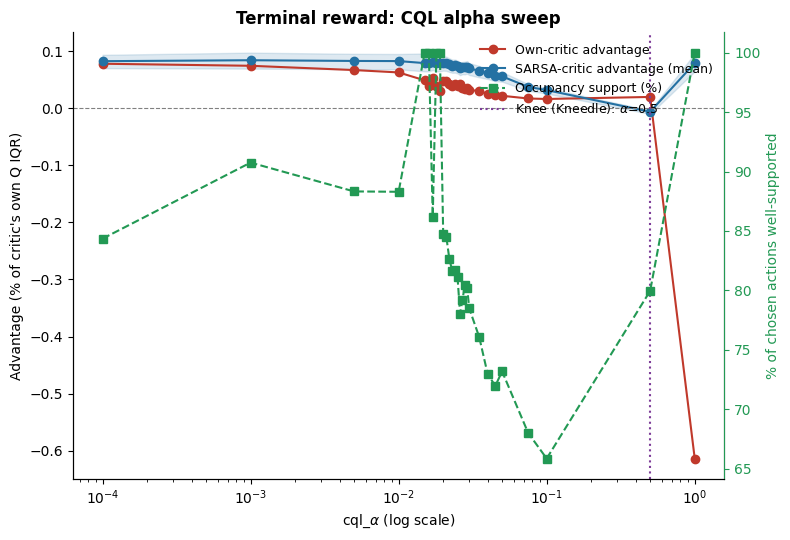

In [35]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_terminal,
    normalized=True, log_scale=True,
    title="Terminal reward: CQL alpha sweep",
    save_path=save_path,
)

# check standard deviation for both model types
Actor magnitude standard deviation across the CQL alpha sweep

To confirm that the architectural fixes addressing magnitude-distribution collapse (Section [X]) generalize across the full range of tested conservatism levels, we examined the actor's fluid and vasopressor magnitude standard deviations (f_std, v_std) as a function of cql_alpha, for both reward formulations. Because the mean std across states can mask a bimodal population (a majority of collapsed, floor-pinned states alongside a minority of much higher values), we report both the mean and the fraction of states at each clamp boundary.

For the health-score-difference reward, floor-collapse was substantial at the lowest tested alpha values: at alpha ≤ 0.001, 77–85% of states had f_std pinned at the clamp floor, despite a mean std (0.40–0.54) that would appear reasonable if considered alone — a clear illustration of why the per-state floor/ceiling fraction, not the mean, is the metric that actually diagnoses collapse. From alpha=0.005 onward — including the entire range retained by our final selection criteria — floor-collapse was absent (0% of states at the floor at every alpha from 0.005 through 1.0), with the fraction of states near the ceiling remaining in a modest single-digit-to-low-teens range throughout. Both f_std and SARSA-critic advantage showed comparable jitter across the same narrow band of alpha values (approximately 0.025–0.05) where we separately identified instability in the advantage and occupancy-support curves, consistent with a single, shared source of single-seed training variance in that region. Floor-collapse reappeared at the opposite end of the tested range, at alpha ≥ 0.5 (82–92% of states at the floor), coinciding with the negative own-critic advantage identified in Section [X] as evidence of degraded training at these values.

Vasopressor's magnitude standard deviation showed more erratic behavior across the sweep, occasionally saturating fully at either the floor or ceiling at individual alpha values with no clear trend. We attribute this to vasopressor's much lower and more variable firing rate relative to fluid, which yields a sparser and noisier gradient signal to its magnitude parameters; since vasopressor is administered in only a small minority of states even at the alphas we selected, this instability is of limited practical consequence for the final policy. By contrast, the terminal-reward model showed near-total, deterministic saturation of both f_std and v_std at the clamp ceiling (exactly 2.7183, with zero variance across states) across nearly the entire tested alpha range, with occasional complete collapse to the floor instead at isolated alpha values. This pattern was present regardless of alpha and did not respond to the same architectural fixes that resolved the analogous issue for health-score reward, providing a direct mechanistic explanation for the persistent, bimodal (0/1) fluid dosing behavior observed for the terminal-reward policy throughout this analysis (Section [Y]), and reinforcing our decision to exclude terminal-reward CQL policies from further consideration.

=== Health-score alpha sweep ===
Floor std (exp(log_std_min=-2.0)) = 0.1353
Ceiling std (exp(log_std_max=1.0)) = 2.7183

alpha=0.0: f_std [mean=0.3772, min=0.1353, max=2.7183, %floor=84.4%, %ceiling=2.2%]  v_std [mean=1.7557, min=0.6904, max=2.1210, %floor=0.0%, %ceiling=0.0%]
alpha=0.0001: f_std [mean=0.4030, min=0.1353, max=2.7183, %floor=84.9%, %ceiling=6.3%]  v_std [mean=1.2578, min=0.3383, max=1.6062, %floor=0.0%, %ceiling=0.0%]
alpha=0.001: f_std [mean=0.5444, min=0.1353, max=2.7183, %floor=76.5%, %ceiling=10.0%]  v_std [mean=0.9915, min=0.3019, max=1.3844, %floor=0.0%, %ceiling=0.0%]
alpha=0.005: f_std [mean=0.7739, min=0.1886, max=2.7183, %floor=0.0%, %ceiling=13.1%]  v_std [mean=0.6053, min=0.4079, max=1.8589, %floor=0.0%, %ceiling=0.0%]
alpha=0.01: f_std [mean=0.7550, min=0.2306, max=2.7183, %floor=0.0%, %ceiling=8.1%]  v_std [mean=0.7865, min=0.5692, max=2.7183, %floor=0.0%, %ceiling=1.1%]
alpha=0.015: f_std [mean=0.7459, min=0.1705, max=2.7183, %floor=0.0%, %ceiling=6.1%]  

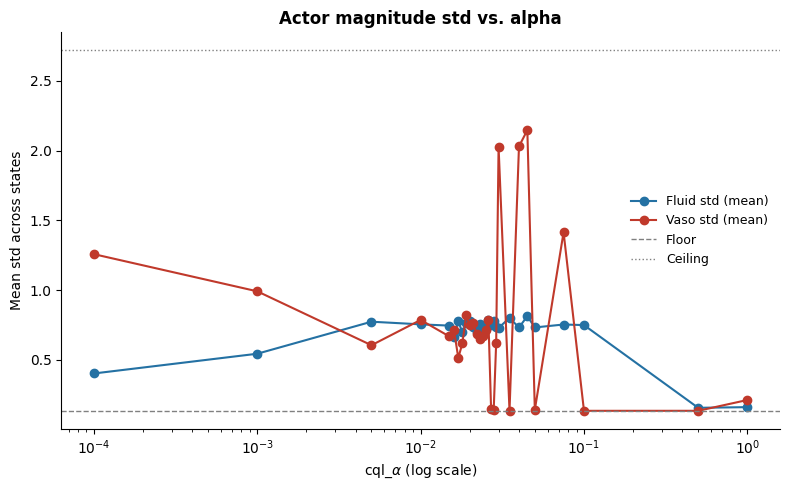

In [29]:
print("=== Health-score alpha sweep ===")
results_std_hs = std_check.check_std_by_alpha(cql_health_score_by_alpha, processors['val'])
fig = std_check.plot_std_by_alpha(results_std_hs, log_x=True, save_path=os.path.join(cql_model_dir, "std_by_alpha_health_score.png"))
fig


=== Terminal alpha sweep ===
Floor std (exp(log_std_min=-2.0)) = 0.1353
Ceiling std (exp(log_std_max=1.0)) = 2.7183

alpha=0.0: f_std [mean=2.7183, min=2.7183, max=2.7183, %floor=0.0%, %ceiling=100.0%]  v_std [mean=2.7183, min=2.7183, max=2.7183, %floor=0.0%, %ceiling=100.0%]
alpha=0.0001: f_std [mean=2.7183, min=2.7183, max=2.7183, %floor=0.0%, %ceiling=100.0%]  v_std [mean=2.7183, min=2.7183, max=2.7183, %floor=0.0%, %ceiling=100.0%]
alpha=0.001: f_std [mean=0.3748, min=0.1353, max=2.7183, %floor=89.9%, %ceiling=8.8%]  v_std [mean=2.4755, min=0.2922, max=2.7183, %floor=0.0%, %ceiling=88.7%]
alpha=0.005: f_std [mean=0.1353, min=0.1353, max=0.1353, %floor=100.0%, %ceiling=0.0%]  v_std [mean=1.5914, min=0.7361, max=2.7183, %floor=0.0%, %ceiling=0.3%]
alpha=0.01: f_std [mean=0.3245, min=0.1353, max=2.7183, %floor=87.2%, %ceiling=0.1%]  v_std [mean=2.7183, min=2.7183, max=2.7183, %floor=0.0%, %ceiling=100.0%]
alpha=0.015: f_std [mean=2.7183, min=2.7183, max=2.7183, %floor=0.0%, %ceiling=

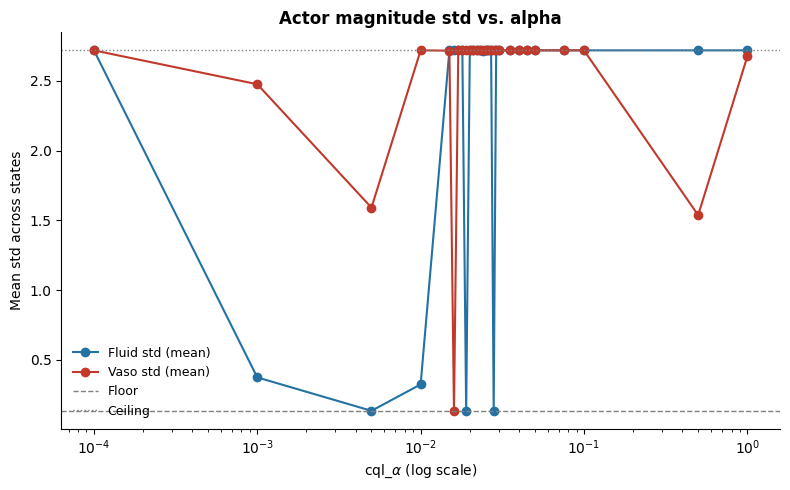

In [30]:
print("\n=== Terminal alpha sweep ===")
results_std_term = std_check.check_std_by_alpha(cql_terminal_by_alpha, processors['val'])
fig = std_check.plot_std_by_alpha(results_std_term, log_x=True, save_path=os.path.join(cql_model_dir, "std_by_alpha_terminal.png"))
fig

# Exclude models with negative own-critic advantage
## 

In [39]:
print("=== Health-score reward ===")
stable_alphas_hs, info_hs = final_select.select_final_candidates(results_health_score, safety_margin=0)

print("\n=== Terminal reward ===")
stable_alphas_term, info_term = final_select.select_final_candidates(results_terminal, safety_margin=0)

=== Health-score reward ===
Own-critic advantage filter (threshold > 0.0, normalized):
  Eligible (27): [0.0, 0.0001, 0.001, 0.005, 0.01, 0.015, 0.016, 0.017, 0.018, 0.019, 0.02, 0.021, 0.022, 0.023, 0.024, 0.025, 0.026, 0.027, 0.028, 0.029, 0.03, 0.035, 0.04, 0.045, 0.05, 0.075, 0.1]
  Excluded (2): [0.5, 1.0]
    alpha=0.5: own-critic advantage = -0.0108
    alpha=1.0: own-critic advantage = -0.0536

SARSA-advantage instability scan (window=3, relative_threshold=0.5):
  window [0.0, 0.0001, 0.001]: mean=0.0798, std=0.0009, ratio=0.01
  window [0.0001, 0.001, 0.005]: mean=0.0716, std=0.0115, ratio=0.16
  window [0.001, 0.005, 0.01]: mean=0.0582, std=0.0157, ratio=0.27
  window [0.005, 0.01, 0.015]: mean=0.0433, std=0.0090, ratio=0.21
  window [0.01, 0.015, 0.016]: mean=0.0363, std=0.0029, ratio=0.08
  window [0.015, 0.016, 0.017]: mean=0.0340, std=0.0004, ratio=0.01
  window [0.016, 0.017, 0.018]: mean=0.0337, std=0.0007, ratio=0.02
  window [0.017, 0.018, 0.019]: mean=0.0336, std=0.0

# plot action distributions

In [40]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

## health score - fluid

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.0: n=17032, mean=0.9659, std=0.1037, median=1.0000, p10=0.8997, p25=0.9995, p75=1.0000, p90=1.0000
  alpha=0.0001: n=17081, mean=0.9499, std=0.1305, median=1.0000, p10=0.7769, p25=0.9987, p75=1.0000, p90=1.0000
  alpha=0.001: n=27437, mean=0.8842, std=0.2141, median=1.0000, p10=0.4432, p25=0.9246, p75=1.0000, p90=1.0000
  alpha=0.005: n=75880, mean=0.5429, std=0.2809, median=0.4466, p10=0.2471, p25=0.3049, p75=0.7994, p90=0.9999
  alpha=0.01: n=89466, mean=0.4707, std=0.2382, median=0.4556, p10=0.1625, p25=0.3465, p75=0.5798, p90=0.8170
  alpha=0.015: n=89896, mean=0.4573, std=0.2157, median=0.4564, p10=0.1819, p25=0.3452, p75=0.5595, p90=0.7190
  alpha=0.016: n=89844, mean=0.4816, std=0.2052, median=0.4686, p10=0.2418, p25=0.3773, p75=0.5799, p90=0.7448
  alpha=0.017: n=89706, mean=0.4528, std=0.2138,

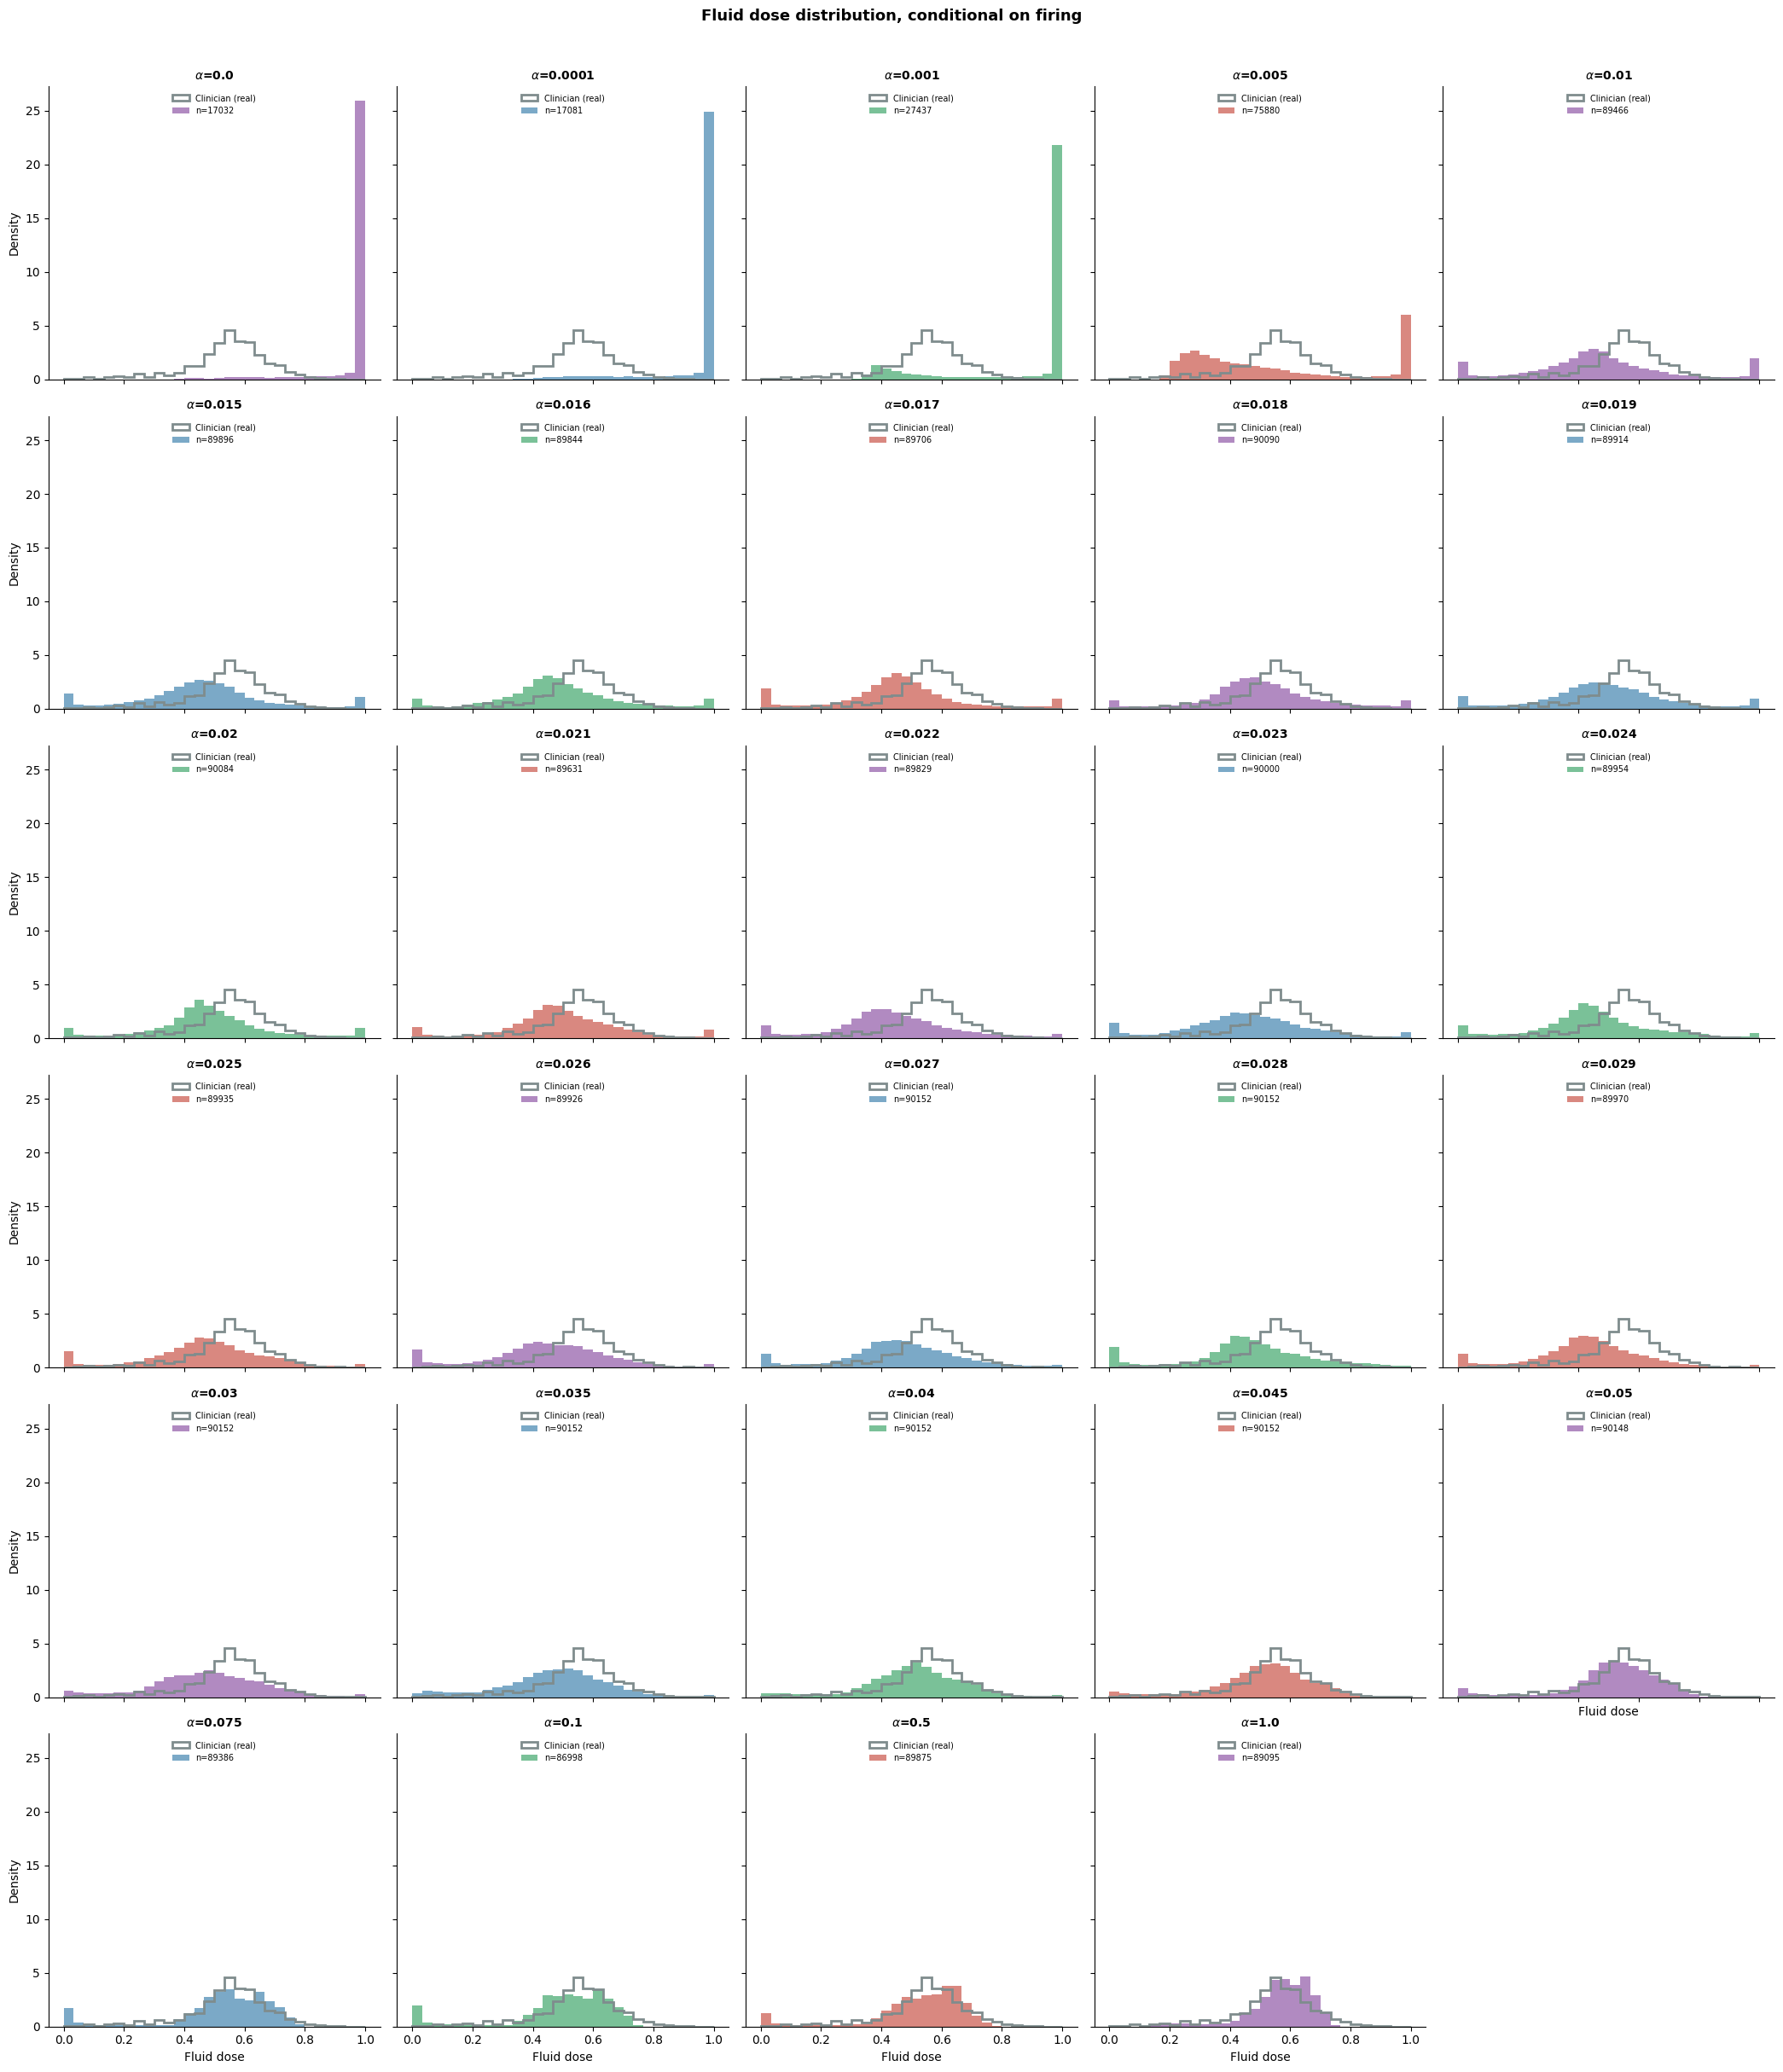

In [55]:
# health-score
fig_hs = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_stable_alphas_health_score.png"),
)

=== Fluid: model dose distribution AT clinician-zero states (n=8225, 9.1% of all states) ===
  alpha=0.0: agrees (recommends ~0) at 92.8% of clinician-zero states; among the 593 disagreements, mean dose=0.9634, median=1.0000
  alpha=0.0001: agrees (recommends ~0) at 93.6% of clinician-zero states; among the 527 disagreements, mean dose=0.9190, median=1.0000
  alpha=0.001: agrees (recommends ~0) at 87.1% of clinician-zero states; among the 1065 disagreements, mean dose=0.8453, median=0.9997
  alpha=0.005: agrees (recommends ~0) at 23.5% of clinician-zero states; among the 6296 disagreements, mean dose=0.4442, median=0.3545
  alpha=0.01: agrees (recommends ~0) at 0.7% of clinician-zero states; among the 8164 disagreements, mean dose=0.3586, median=0.3556
  alpha=0.015: agrees (recommends ~0) at 0.4% of clinician-zero states; among the 8192 disagreements, mean dose=0.3447, median=0.3451
  alpha=0.016: agrees (recommends ~0) at 0.3% of clinician-zero states; among the 8203 disagreements, m

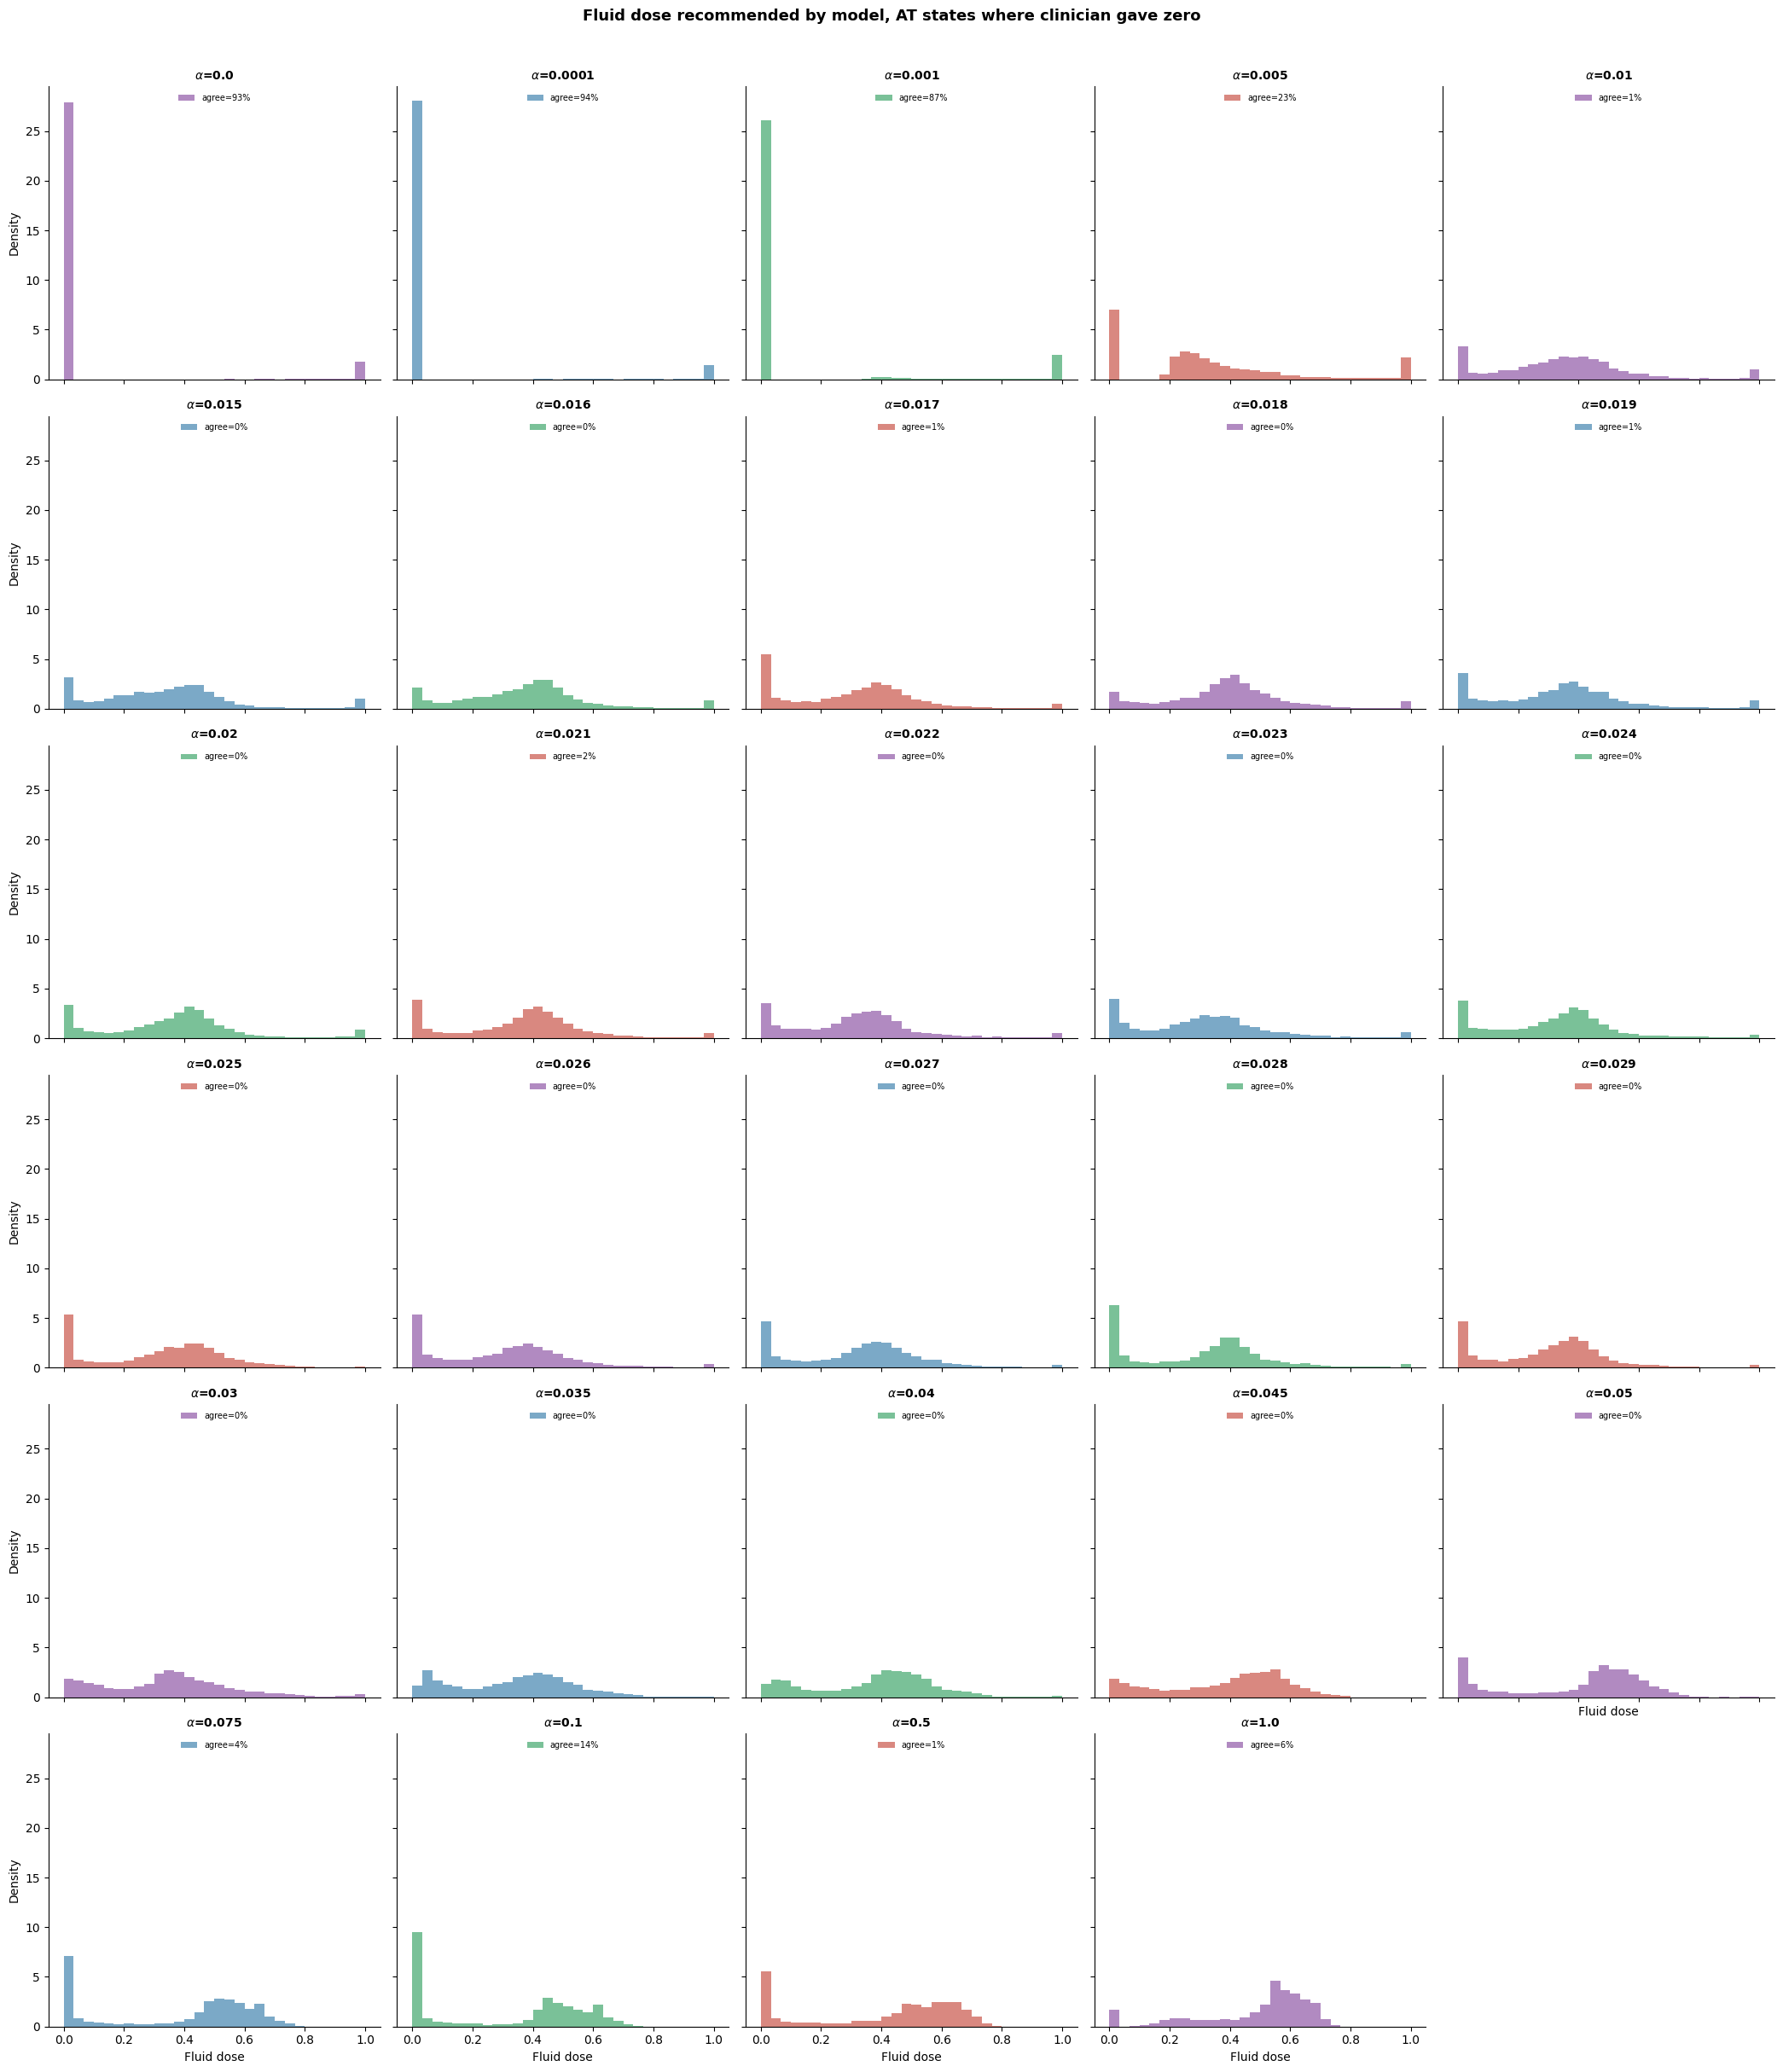

In [54]:
fig = dose_hist.plot_dose_histograms_at_clinician_zero(
    cql_health_score_by_alpha,  # or cql_terminal_by_alpha
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_at_clinician_zero_health_score.png"),
)

## health-score vaso

=== Vaso dose distribution summary (nonzero doses only) ===
  Clinician (real): n=7484, mean=0.2569, std=0.1127, median=0.2319, p10=0.1552, p25=0.1718, p75=0.2971, p90=0.4037
  alpha=0.0: no nonzero doses
  alpha=0.0001: no nonzero doses
  alpha=0.001: no nonzero doses
  alpha=0.005: no nonzero doses
  alpha=0.01: no nonzero doses
  alpha=0.015: no nonzero doses
  alpha=0.016: no nonzero doses
  alpha=0.017: n=63, mean=0.0066, std=0.0060, median=0.0046, p10=0.0017, p25=0.0025, p75=0.0081, p90=0.0155
  alpha=0.018: no nonzero doses
  alpha=0.019: no nonzero doses
  alpha=0.02: no nonzero doses
  alpha=0.021: no nonzero doses
  alpha=0.022: no nonzero doses
  alpha=0.023: no nonzero doses
  alpha=0.024: no nonzero doses
  alpha=0.025: no nonzero doses
  alpha=0.026: no nonzero doses
  alpha=0.027: n=20745, mean=0.0975, std=0.1030, median=0.0565, p10=0.0094, p25=0.0200, p75=0.1409, p90=0.2605
  alpha=0.028: n=21790, mean=0.0918, std=0.0941, median=0.0578, p10=0.0054, p25=0.0170, p75=0.139

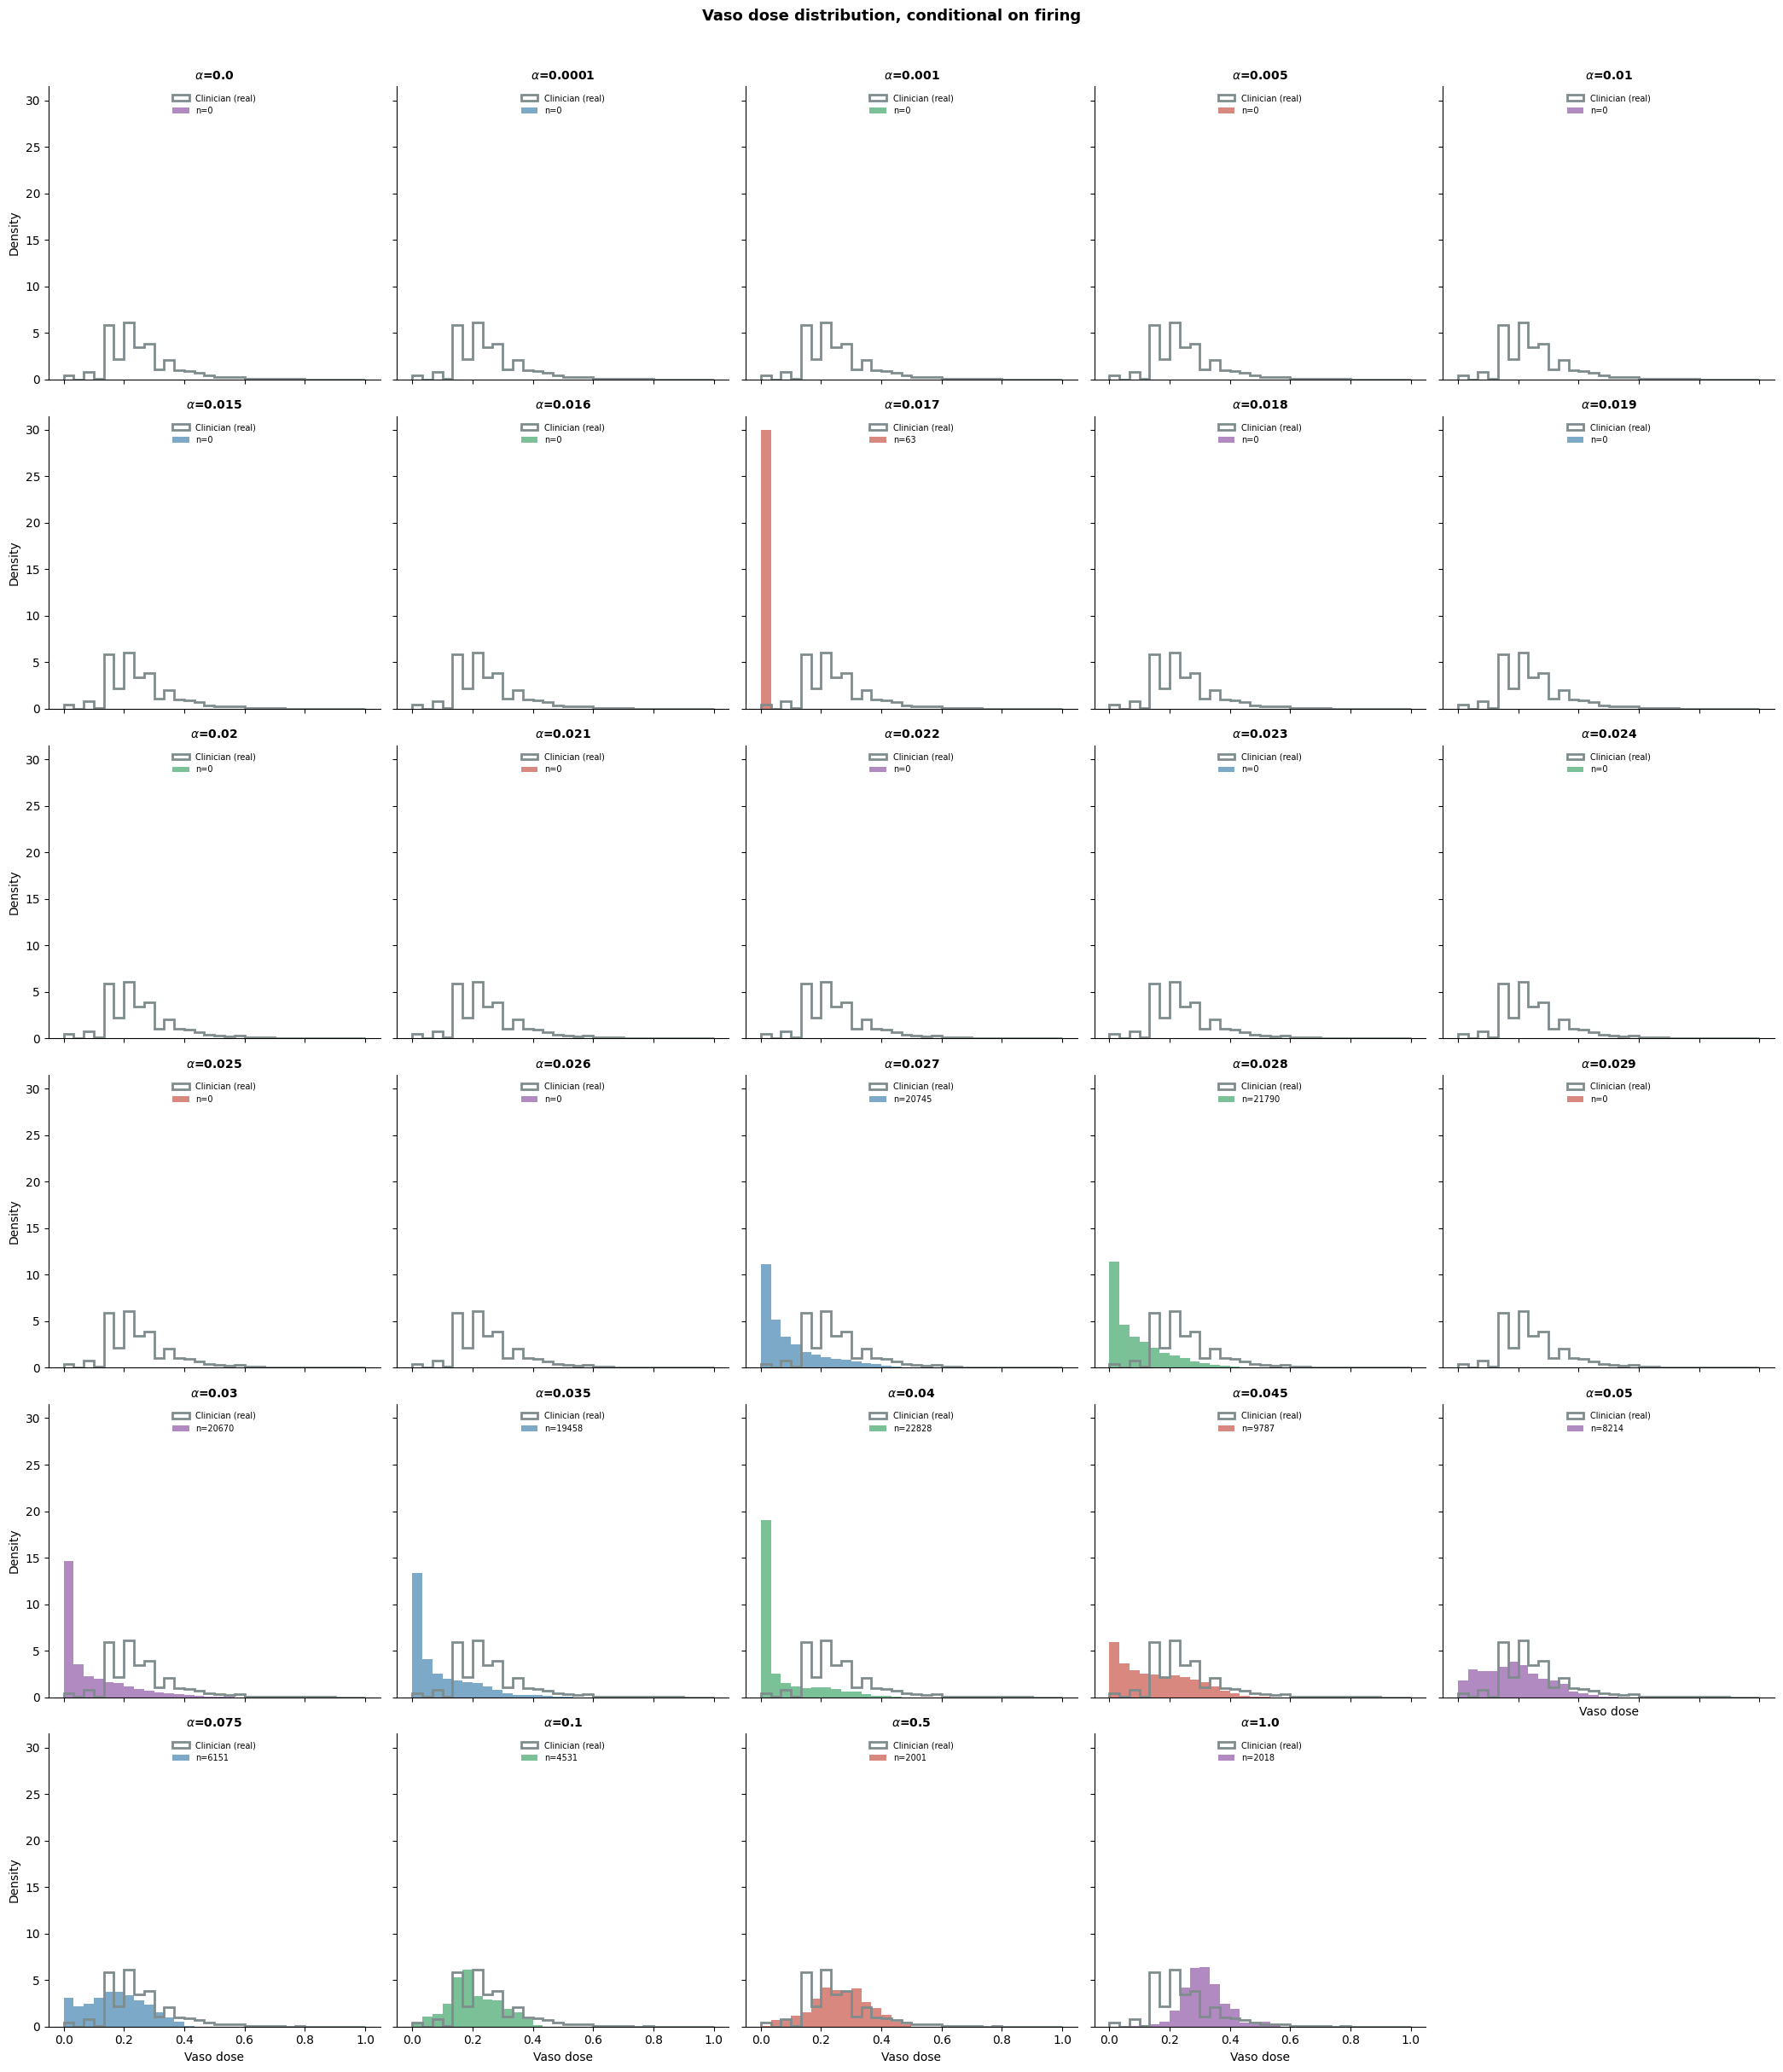

In [51]:
# --- Vaso, nonzero-conditional shape (given the clinician fired, what did it look like,
#     vs. what does the model recommend on the rare occasions it fires) ---
fig_vaso_nonzero_hs = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_vaso_health_score.png"),
)


=== Vaso: model dose distribution AT clinician-zero states (n=82668, 91.7% of all states) ===
  alpha=0.0: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.0001: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.001: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.005: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.01: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.015: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.016: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.017: agrees (recommends ~0) at 100.0% of clinician-zero states; among the 2 disagreements, mean dose=0.0026, median=0.0026
  alpha=0.018: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.019: agrees (recommends ~0) a

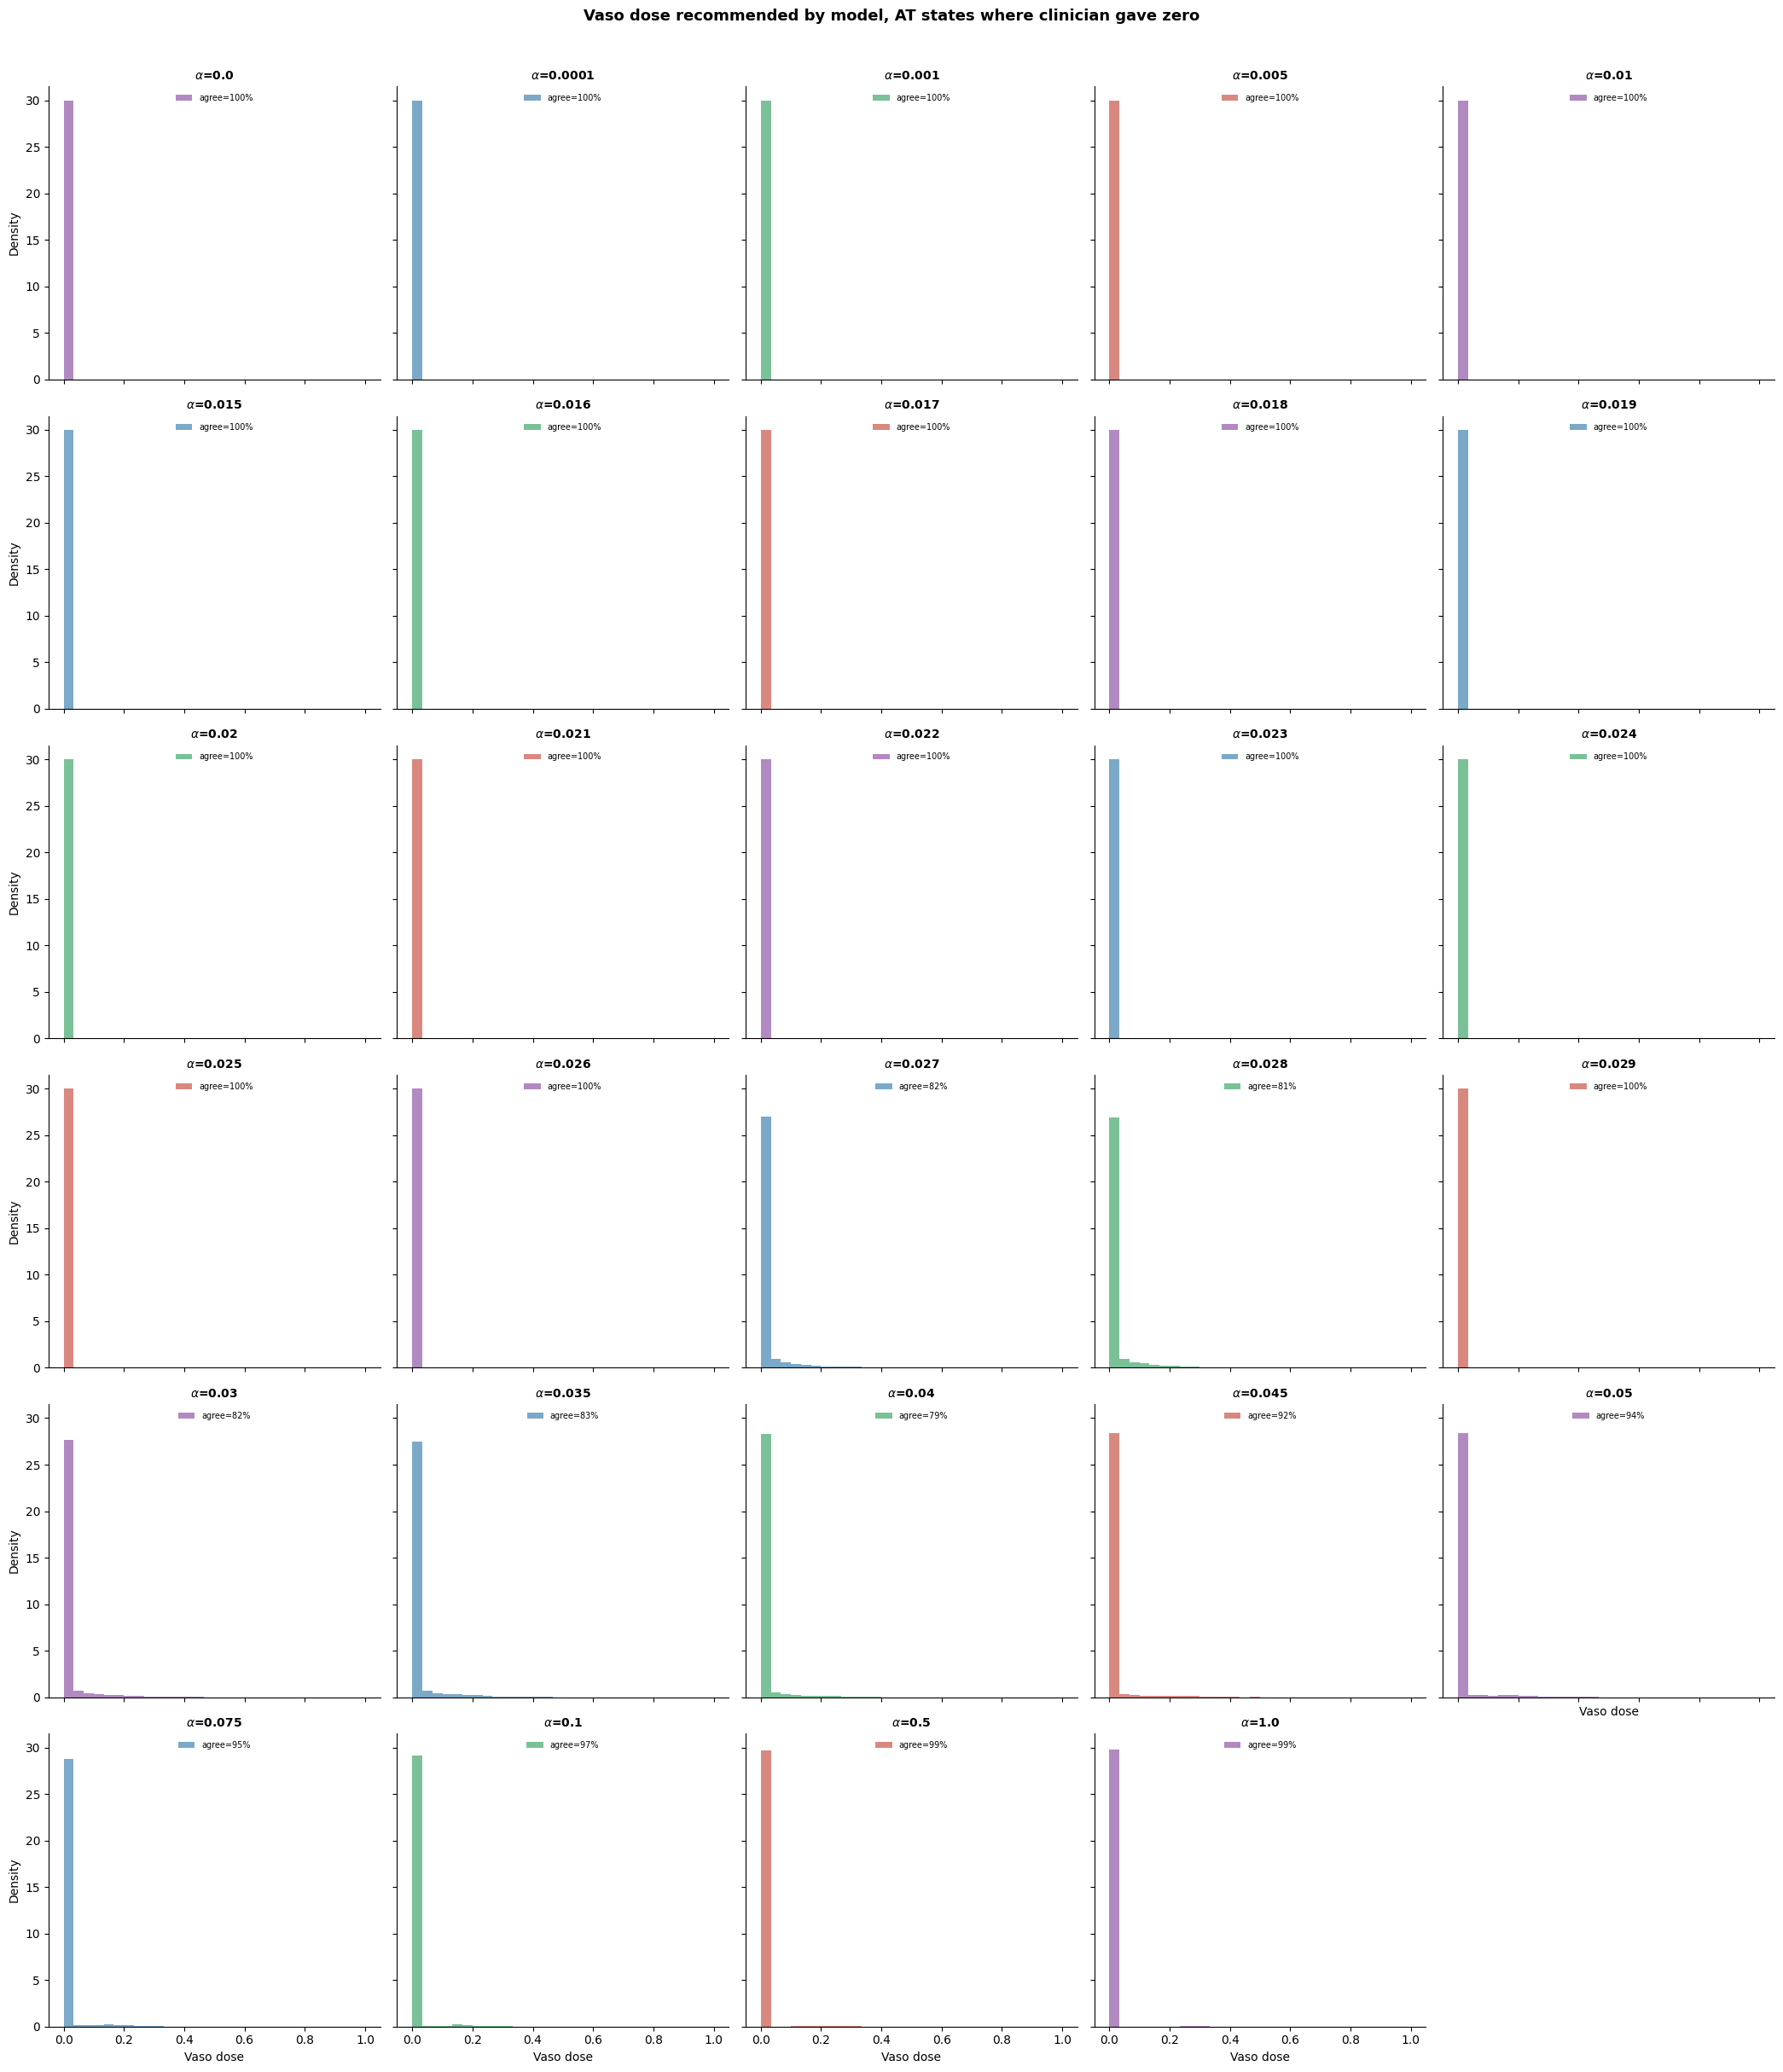

In [53]:
# --- Vaso, at clinician-zero states: does the model ever disagree and recommend
#     nonzero vaso where the clinician withheld it entirely? ---
fig_vaso_zero_hs = dose_hist.plot_dose_histograms_at_clinician_zero(
    cql_health_score_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "vaso_at_clinician_zero_health_score.png"),
)

## terminal - fluid

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.0: n=10784, mean=0.8939, std=0.2903, median=1.0000, p10=0.3729, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.0001: n=10817, mean=0.8872, std=0.2978, median=1.0000, p10=0.2398, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.001: n=9959, mean=0.9272, std=0.2454, median=1.0000, p10=0.9718, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.005: n=13073, mean=0.9128, std=0.2670, median=1.0000, p10=0.8224, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.01: n=13105, mean=0.9107, std=0.2695, median=1.0000, p10=0.7798, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.015: no nonzero doses
  alpha=0.016: no nonzero doses
  alpha=0.017: n=15102, mean=0.9383, std=0.2282, median=1.0000, p10=0.9989, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.018: no nonzero doses
  alpha=0.019: no nonzero doses
  alpha=0.02: n=16992, mean=0.93

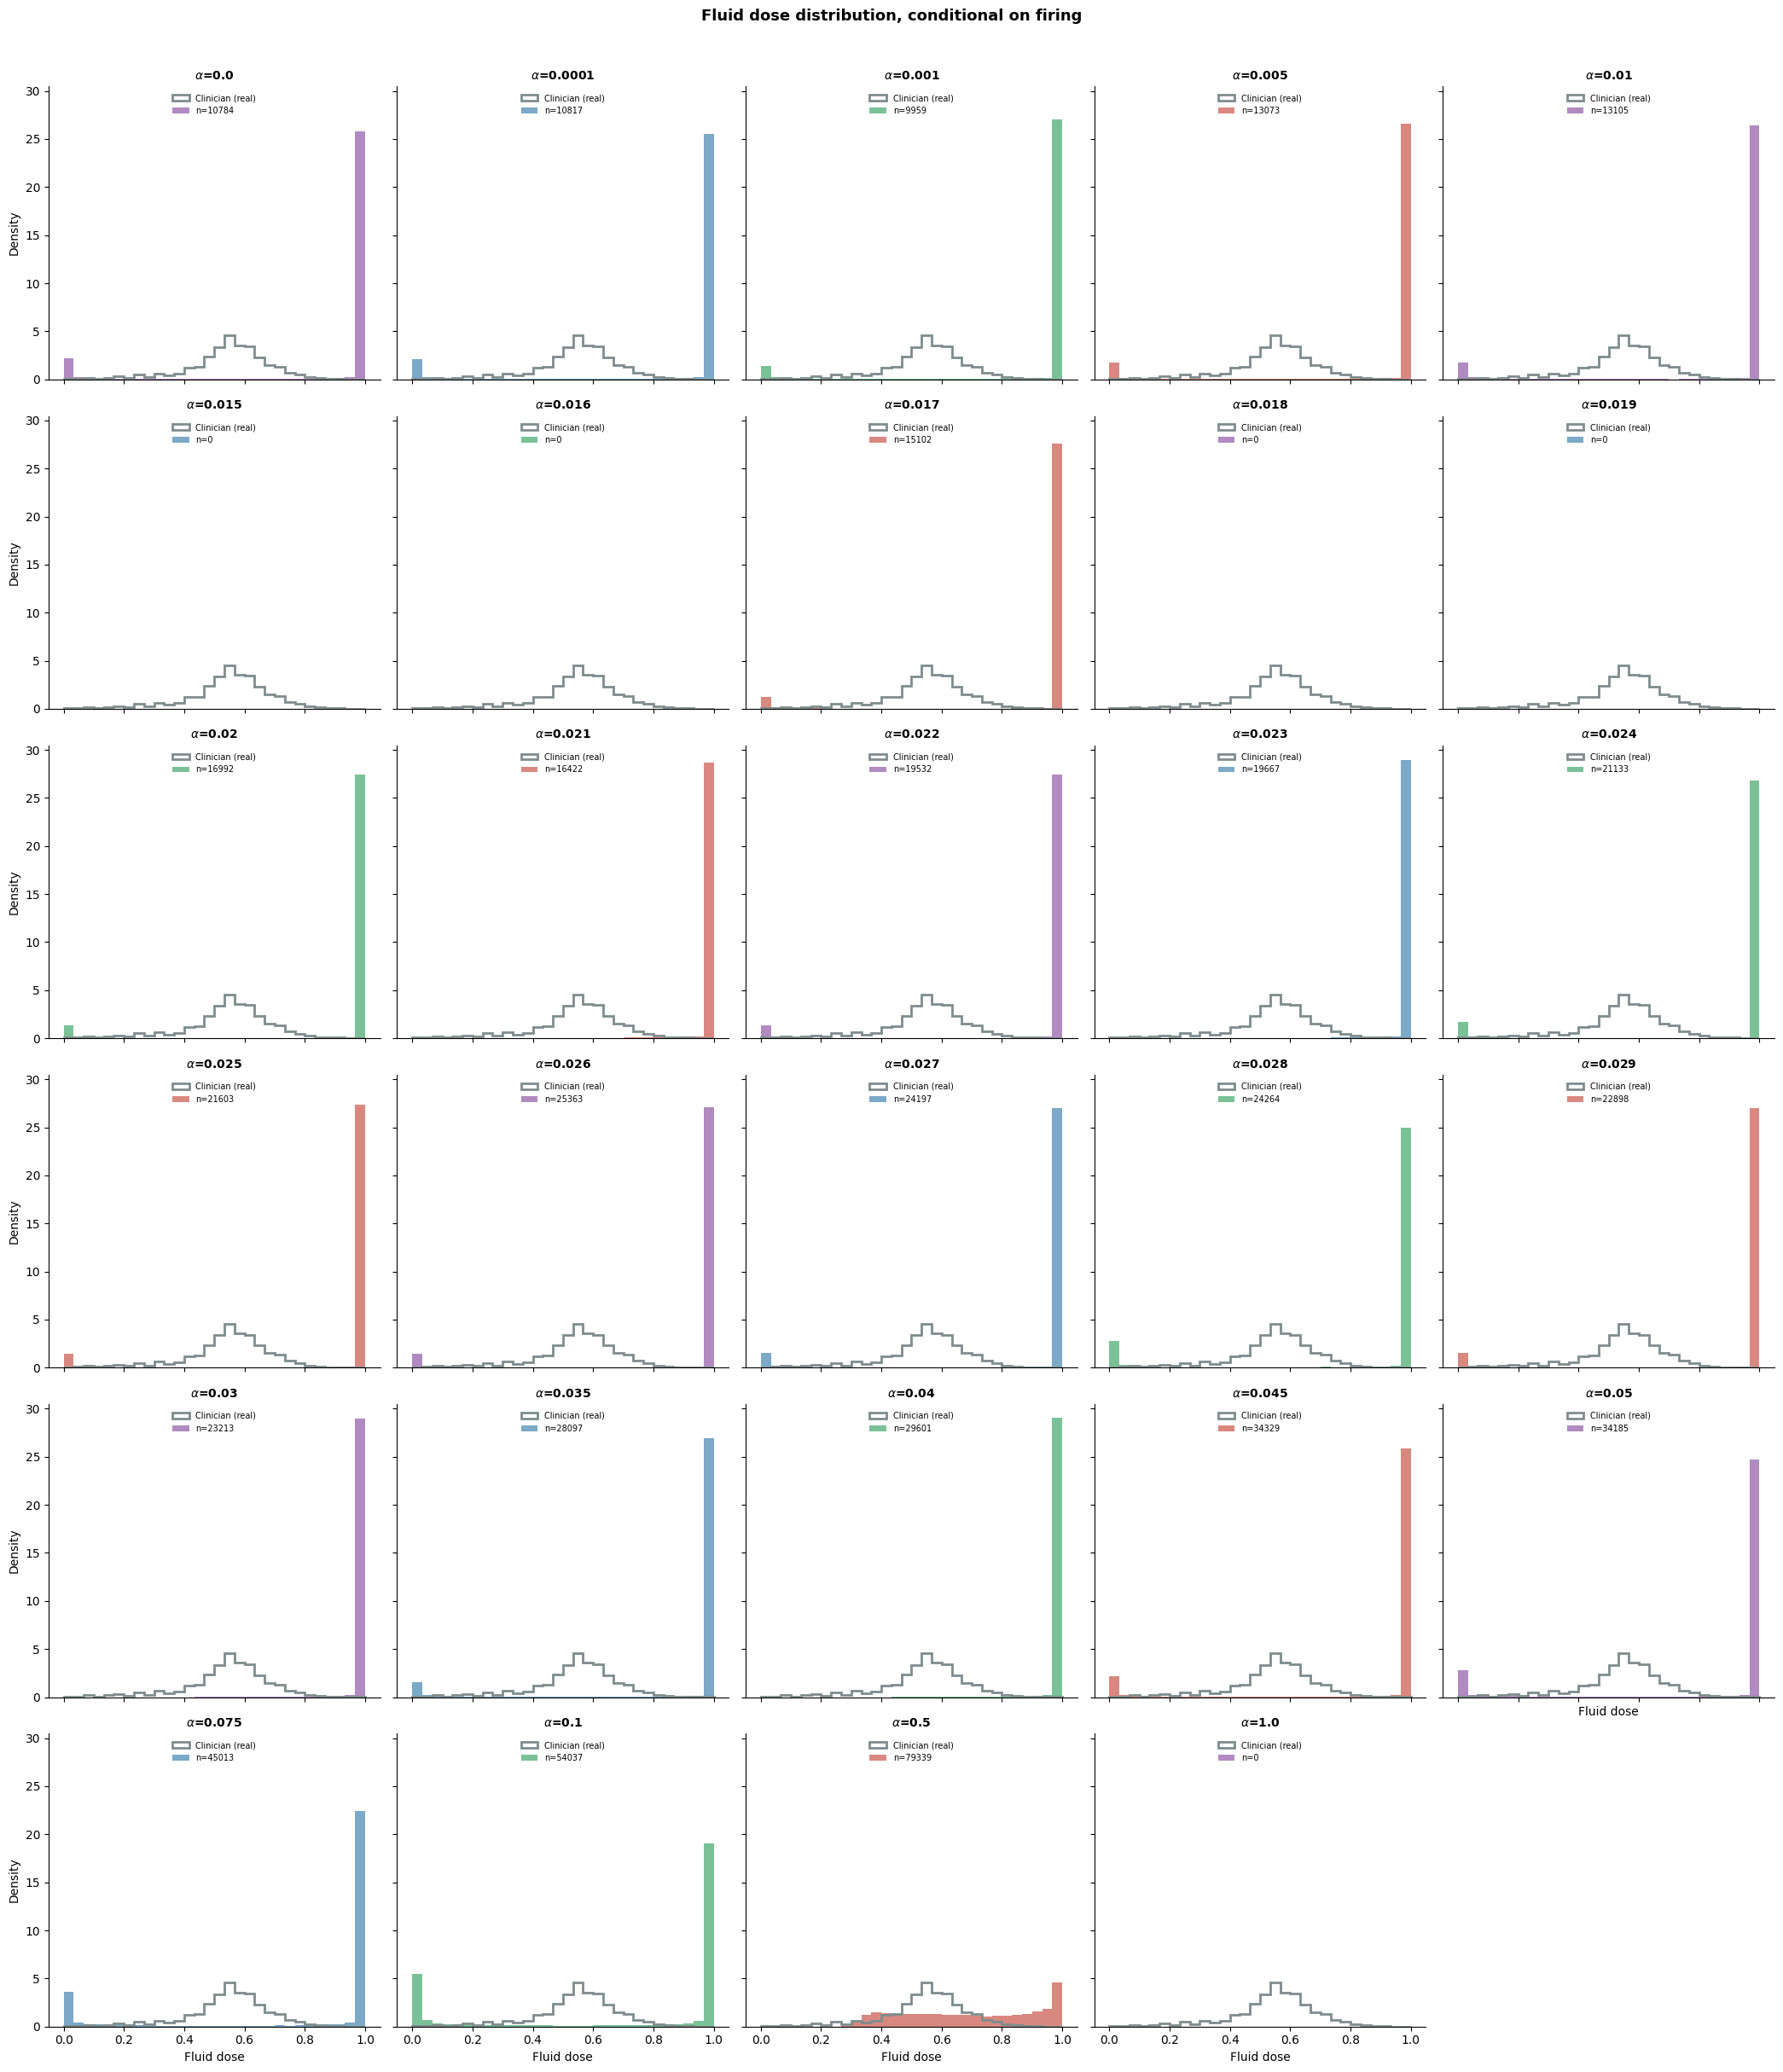

In [56]:
# terminal
fig_term = dose_hist.plot_dose_histograms(
    cql_terminal_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_stable_alphas_terminal.png"),
)

=== Fluid: model dose distribution AT clinician-zero states (n=8225, 9.1% of all states) ===
  alpha=0.0: agrees (recommends ~0) at 97.7% of clinician-zero states; among the 187 disagreements, mean dose=0.8175, median=1.0000
  alpha=0.0001: agrees (recommends ~0) at 97.4% of clinician-zero states; among the 213 disagreements, mean dose=0.8244, median=1.0000
  alpha=0.001: agrees (recommends ~0) at 97.8% of clinician-zero states; among the 182 disagreements, mean dose=0.8781, median=1.0000
  alpha=0.005: agrees (recommends ~0) at 96.7% of clinician-zero states; among the 271 disagreements, mean dose=0.8874, median=1.0000
  alpha=0.01: agrees (recommends ~0) at 96.5% of clinician-zero states; among the 287 disagreements, mean dose=0.8756, median=1.0000
  alpha=0.015: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.016: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.017: agrees (recommends ~0) at 95.4% of clini

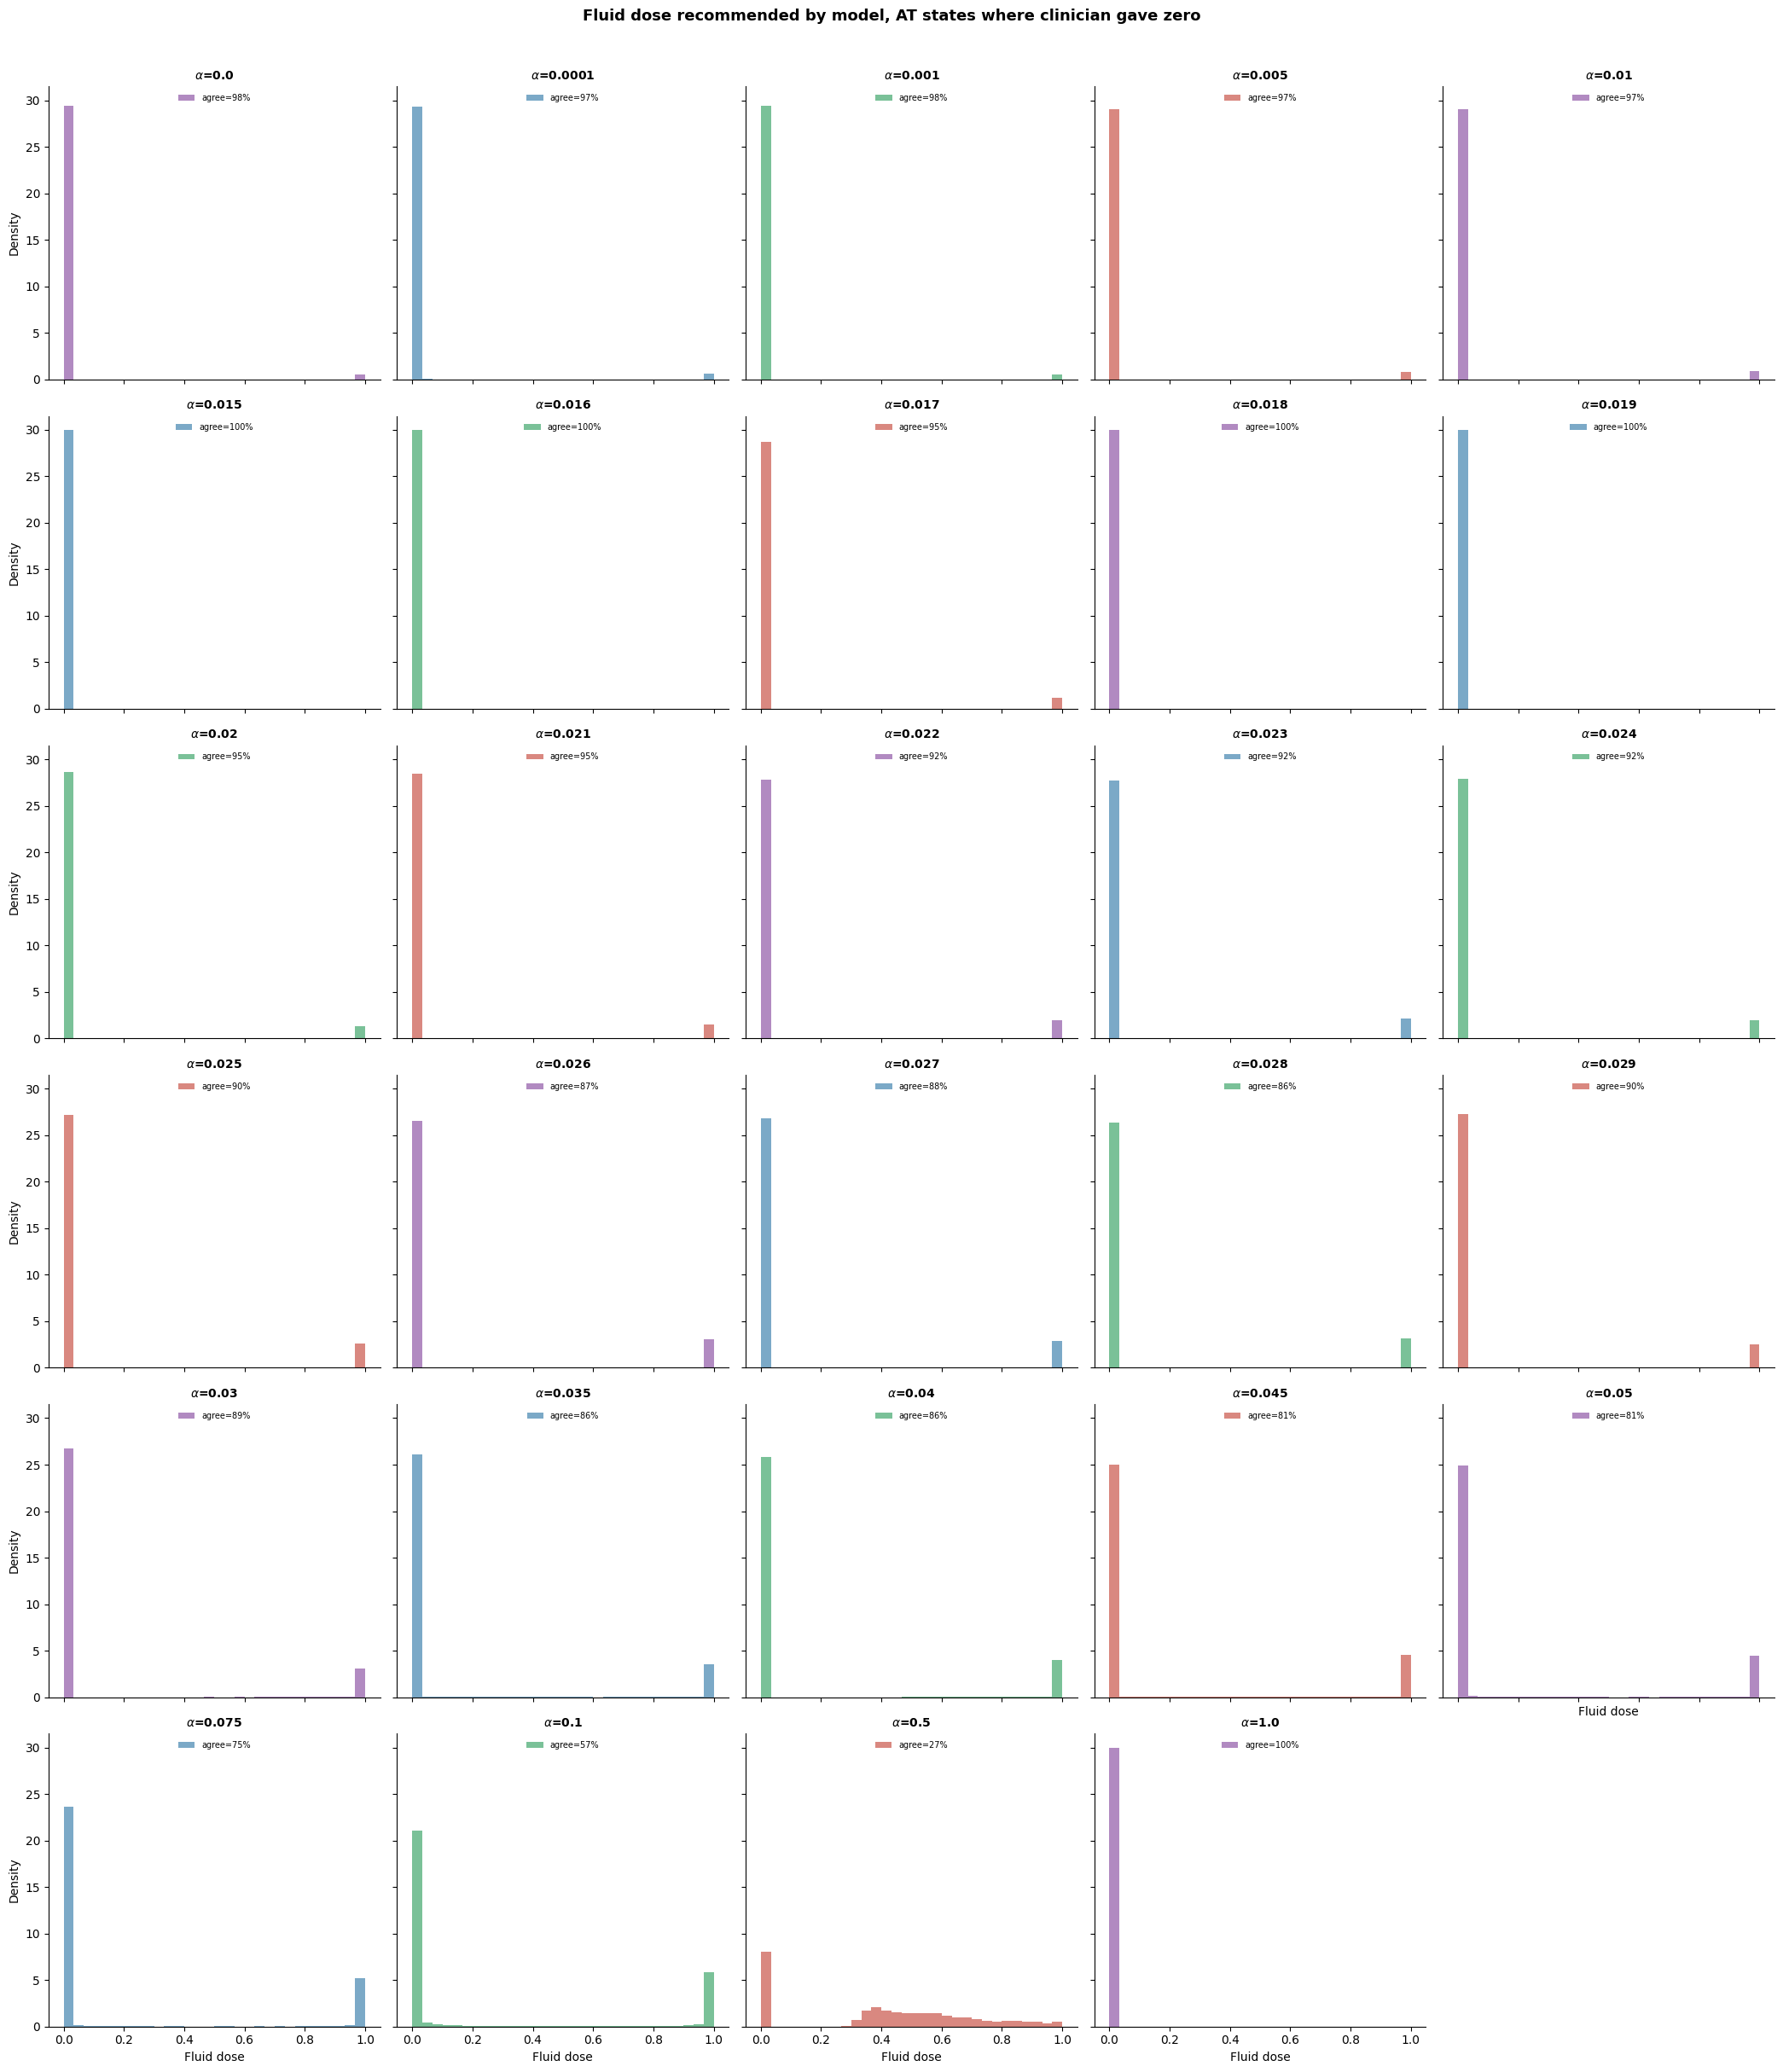

In [57]:
fig = dose_hist.plot_dose_histograms_at_clinician_zero(
    cql_terminal_by_alpha,  
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_at_clinician_zero_terminal.png"),
)

## terminal - vaso

=== Vaso dose distribution summary (nonzero doses only) ===
  Clinician (real): n=7484, mean=0.2569, std=0.1127, median=0.2319, p10=0.1552, p25=0.1718, p75=0.2971, p90=0.4037
  alpha=0.0: n=9415, mean=1.0000, std=0.0000, median=1.0000, p10=1.0000, p25=1.0000, p75=1.0000, p90=1.0000
  alpha=0.0001: n=5618, mean=0.9869, std=0.0383, median=1.0000, p10=0.9630, p25=0.9969, p75=1.0000, p90=1.0000
  alpha=0.001: no nonzero doses
  alpha=0.005: no nonzero doses
  alpha=0.01: no nonzero doses
  alpha=0.015: no nonzero doses
  alpha=0.016: no nonzero doses
  alpha=0.017: no nonzero doses
  alpha=0.018: no nonzero doses
  alpha=0.019: no nonzero doses
  alpha=0.02: no nonzero doses
  alpha=0.021: no nonzero doses
  alpha=0.022: no nonzero doses
  alpha=0.023: no nonzero doses
  alpha=0.024: no nonzero doses
  alpha=0.025: no nonzero doses
  alpha=0.026: no nonzero doses
  alpha=0.027: no nonzero doses
  alpha=0.028: no nonzero doses
  alpha=0.029: no nonzero doses
  alpha=0.03: no nonzero doses
 

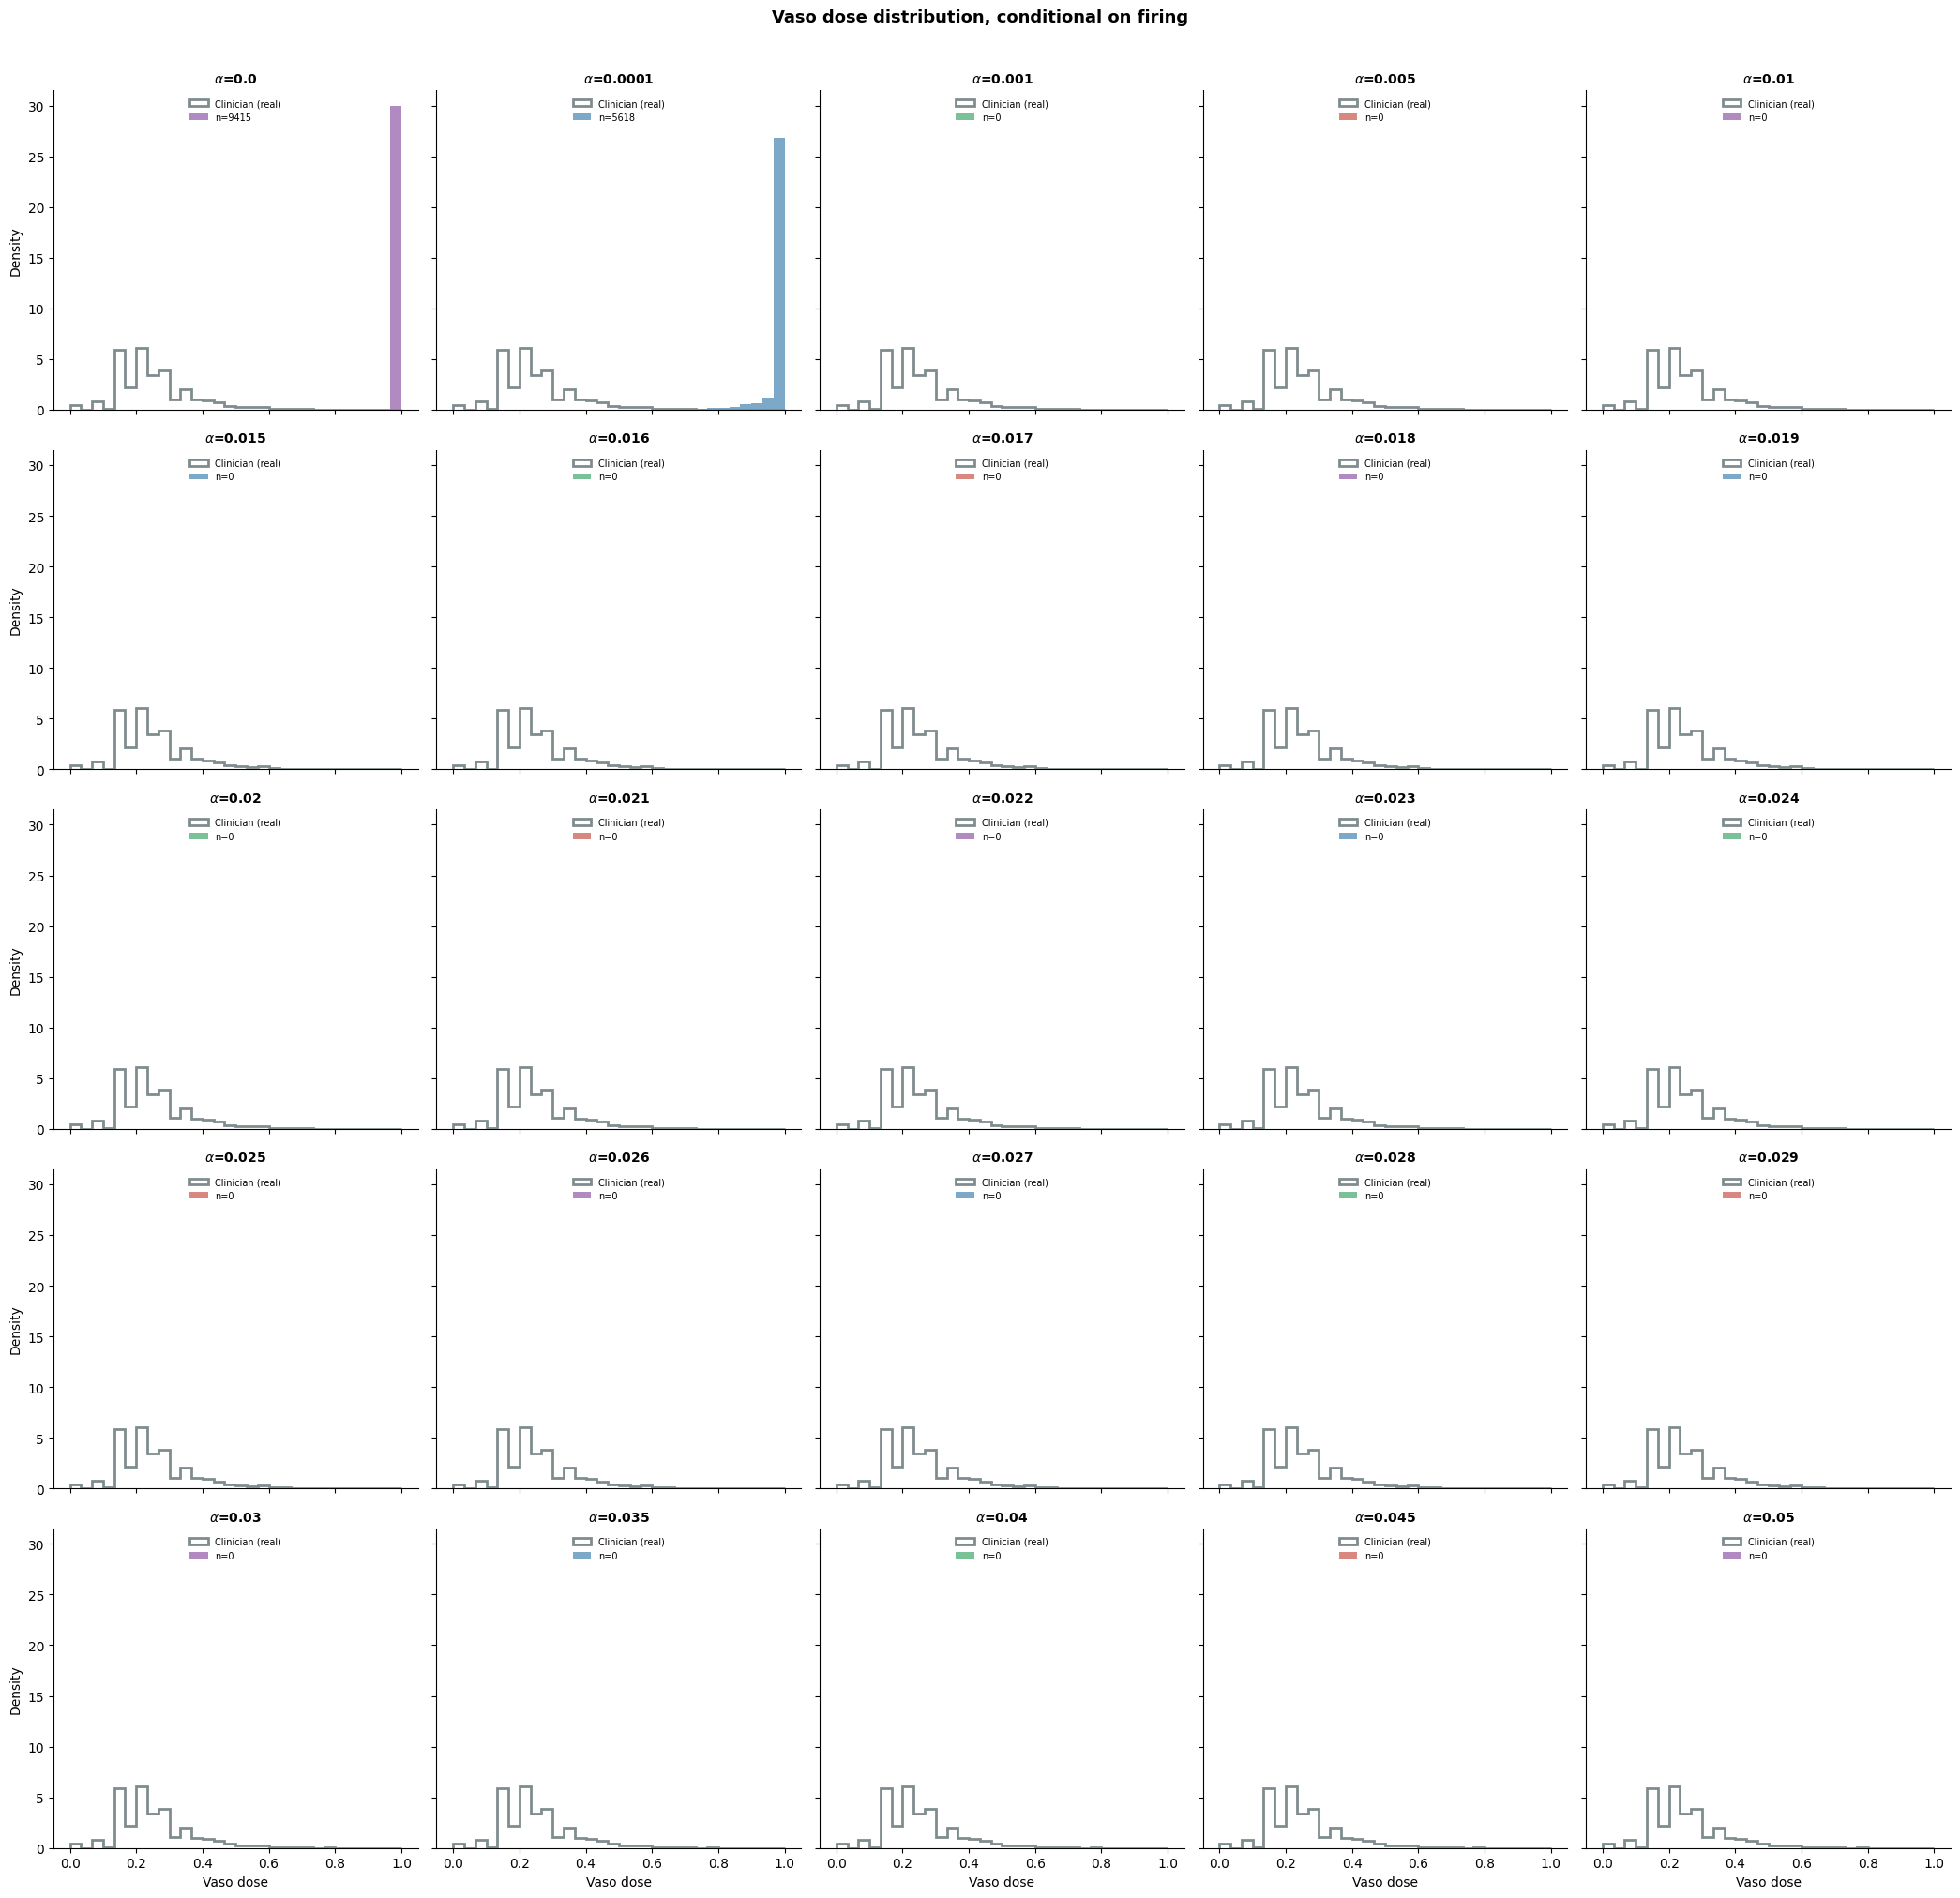

In [49]:
# same two, for terminal
fig_vaso_nonzero_term = dose_hist.plot_dose_histograms(
    cql_terminal_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    alphas_to_show=stable_alphas_term,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_vaso_terminal.png"),
)

=== Vaso: model dose distribution AT clinician-zero states (n=82668, 91.7% of all states) ===
  alpha=0.0: agrees (recommends ~0) at 89.3% of clinician-zero states; among the 8838 disagreements, mean dose=1.0000, median=1.0000
  alpha=0.0001: agrees (recommends ~0) at 93.5% of clinician-zero states; among the 5404 disagreements, mean dose=0.9873, median=1.0000
  alpha=0.001: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.005: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.01: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.015: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.016: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.017: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.018: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreem

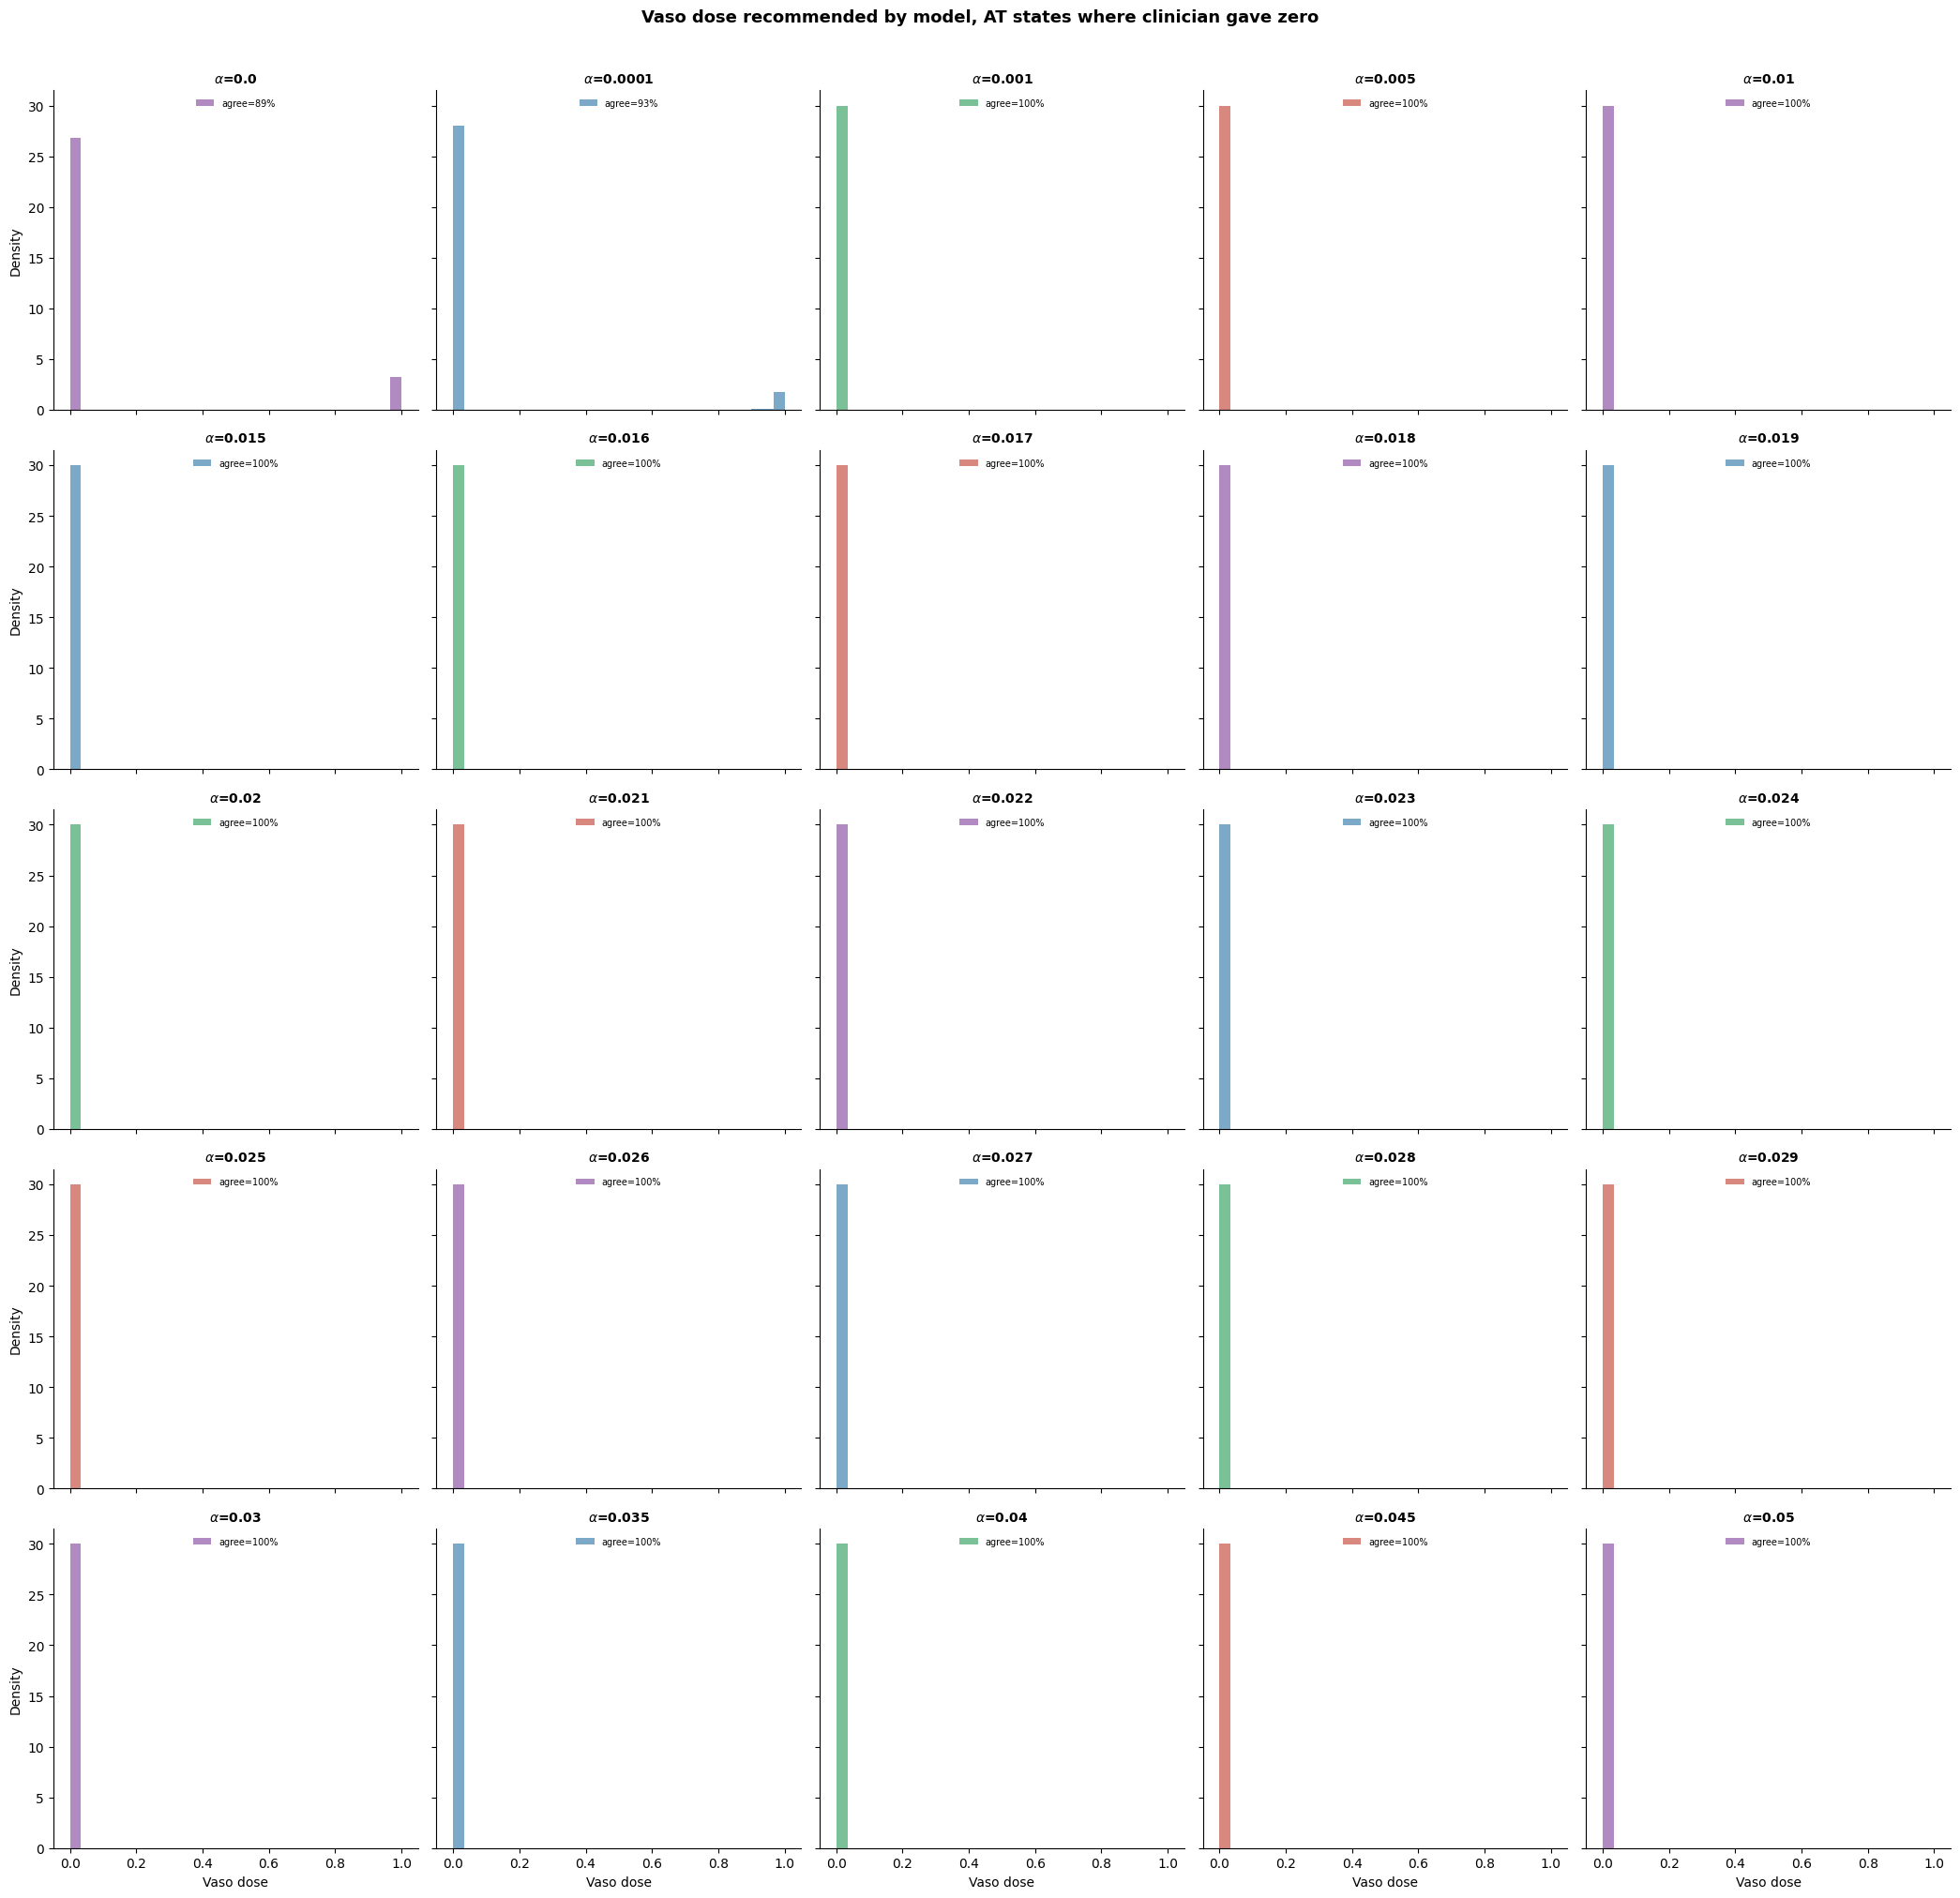

In [58]:
fig_vaso_zero_term = dose_hist.plot_dose_histograms_at_clinician_zero(
    cql_terminal_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=1, dim_name="Vaso",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "vaso_at_clinician_zero_terminal.png"),
)

# select final health score model
## terminal models clearly pathological from action distributions

In [60]:
ranked_hs = final_select.rank_stable_candidates(results_health_score, stable_alphas_hs)
final_alpha_hs = ranked_hs[0][0]

Stable candidates ranked by occupancy (descending, other metric as tie-break):
  alpha=0.022: occupancy=98.0%, SARSA-advantage=0.0391
  alpha=0.024: occupancy=97.7%, SARSA-advantage=0.0403
  alpha=0.023: occupancy=97.7%, SARSA-advantage=0.0396
  alpha=0.021: occupancy=96.9%, SARSA-advantage=0.0308
  alpha=0.018: occupancy=96.2%, SARSA-advantage=0.0330
  alpha=0.02: occupancy=96.0%, SARSA-advantage=0.0328
  alpha=0.017: occupancy=95.9%, SARSA-advantage=0.0336
  alpha=0.016: occupancy=95.7%, SARSA-advantage=0.0346
  alpha=0.019: occupancy=95.7%, SARSA-advantage=0.0342
  alpha=0.015: occupancy=95.6%, SARSA-advantage=0.0339
  alpha=0.01: occupancy=92.8%, SARSA-advantage=0.0404
  alpha=0.0001: occupancy=85.8%, SARSA-advantage=0.0808
  alpha=0.0: occupancy=85.2%, SARSA-advantage=0.0801
  alpha=0.005: occupancy=83.3%, SARSA-advantage=0.0555
  alpha=0.001: occupancy=80.2%, SARSA-advantage=0.0786

Top candidate: alpha=0.022


# STOP HERE AND RUN 5 SEEDS AT THE TOP CANDIDATE ALPHA VALUE

In [33]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )

    # print cql value for this model
    print(f"Loaded CQL health-score model from {model_dir}, cql_alpha={health_score_hyperparams['cql_alpha']}")

    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))


Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-235751_073683e4
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-225924_24f16bd0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260913_223042/unknown_cx3-20-1_20260913-232805_87a9aaa

### "seed 4 showed a degenerate vaso magnitude distribution (bimodal at clamp extremes); this had negligible practical effect given vaso's near-zero firing rate for this seed, but is noted as a seed-level irregularity."

Floor std = 0.1353, Ceiling std = 2.7183

Seed    Drug        mean     std     min     max  median   %floor   %ceil
-----------------------------------------------------------------------
1       Fluid     0.7548  0.5652  0.1982  2.7183  0.5828     0.0%    4.6%
1       Vaso      0.7637  0.2906  0.4735  2.7183  0.6605     0.0%    0.3%
2       Fluid     0.7164  0.5346  0.2005  2.7183  0.5360     0.0%    4.0%
2       Vaso      0.5793  0.1771  0.3010  1.7930  0.5267     0.0%    0.0%
3       Fluid     0.7475  0.5617  0.1767  2.7183  0.5945     0.0%    5.2%
3       Vaso      0.8154  0.4384  0.4172  2.7183  0.6710     0.0%    3.0%
4       Fluid     0.8077  0.6236  0.1814  2.7183  0.5960     0.0%    6.1%
4       Vaso      1.9080  1.0316  0.1353  2.7183  2.7183     7.6%   53.8%
5       Fluid     0.7952  0.6323  0.1929  2.7183  0.5953     0.0%    7.2%
5       Vaso      0.6683  0.3050  0.3487  2.7183  0.5507     0.0%    0.1%

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_wi

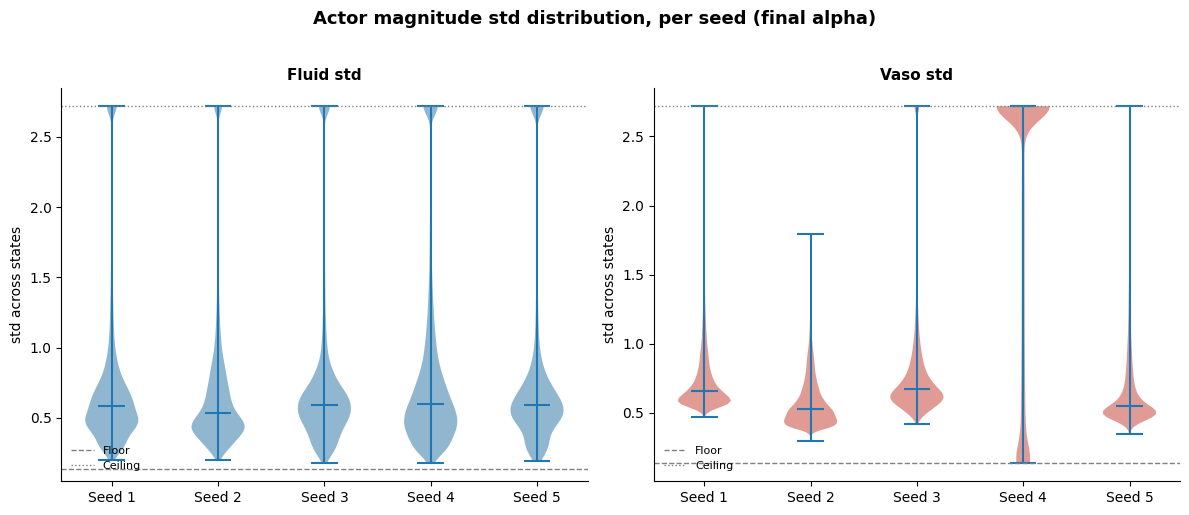

In [39]:
fig = std_check.plot_std_distributions_by_seed(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    save_path=os.path.join(cql_model_dir, "std_distributions_by_seed_health_score.png"),
)
fig

"Co-occurrence of ceiling-saturated magnitude standard deviation and near-maximal fluid dosing

We tested whether the residual near-maximal (>0.9) fluid dose recommendations identified throughout this analysis co-occur with states where the actor's fluid magnitude standard deviation is saturated at its clamp ceiling, on the held-out test set, across all 5 final seeds. A meaningful and consistent association was present: 41–74% of high-dose states also showed ceiling-saturated magnitude std (mean ≈ 55%, seed 2 the notable outlier at 74%), while a smaller but still non-trivial 14–43% of ceiling-saturated states corresponded to a high-dose recommendation. This asymmetry indicates that magnitude-variance saturation is a broader phenomenon than the extreme-dose pathology specifically — most ceiling-saturated states do not in fact yield a near-maximal dose — but that a substantial minority-to-majority of the extreme-dose recommendations are accompanied by this internal saturation signature, consistent with both symptoms arising from a shared underlying instability in the actor's magnitude parameterization at these states, rather than being independent phenomena.

Given this partial but incomplete overlap, we do not consider magnitude standard deviation alone a sufficiently sensitive or specific signal to serve as a stand-alone clinical safety flag: using it in isolation would miss a substantial fraction of the problematic recommendations (those without ceiling-saturated std) while over-flagging a larger set of states where saturation is present but the resulting dose is unremarkable. We instead propose data-support (occupancy) at the recommended dose, evaluated per-recommendation against the training distribution stratified by patient severity, as the primary mechanism for flagging low-confidence recommendations to clinicians (Section [X]); the std/dose co-occurrence result reported here is presented as corroborating mechanistic evidence for the origin of the residual extreme-dose behavior, not as an alternative or additional clinical safeguard.

This association was directionally consistent but showed some variability across seeds and evaluation splits (e.g., seed 2's overlap fraction was 49.8% on the validation set and 74.2% on the held-out test set for the same trained model), consistent with sampling noise in these relatively small sub-populations rather than genuine seed-level instability."

In [40]:
for seed_idx, _ in enumerate(cql_health_score_fixed_alpha_models):
    print(f"Checking std dose co-occurrence for seed {seed_idx}...")
    ceiling_mask, high_dose_mask = std_check.check_std_dose_cooccurrence(
        cql_health_score_fixed_alpha_models[seed_idx],  # one seed at a time
        processors['test'],
        dim=0,  # fluid
    )

Checking std dose co-occurrence for seed 0...
Ceiling-std states: 5375 (4.61% of all states)
High-dose (>0.9) states: 2453 (2.10% of all states)
States that are BOTH: 1207
  Fraction of ceiling-std states that are ALSO high-dose: 22.5%
  Fraction of high-dose states that are ALSO ceiling-std: 49.2%
Checking std dose co-occurrence for seed 1...
Ceiling-std states: 4682 (4.01% of all states)
High-dose (>0.9) states: 1649 (1.41% of all states)
States that are BOTH: 681
  Fraction of ceiling-std states that are ALSO high-dose: 14.5%
  Fraction of high-dose states that are ALSO ceiling-std: 41.3%
Checking std dose co-occurrence for seed 2...
Ceiling-std states: 6058 (5.19% of all states)
High-dose (>0.9) states: 1334 (1.14% of all states)
States that are BOTH: 990
  Fraction of ceiling-std states that are ALSO high-dose: 16.3%
  Fraction of high-dose states that are ALSO ceiling-std: 74.2%
Checking std dose co-occurrence for seed 3...
Ceiling-std states: 7111 (6.10% of all states)
High-dose

# kneedle - no longer using
Ref: Satopaa, V., Albrecht, J., Irwin, D., & Barker, B. (2011). "Finding a 'kneedle' in a haystack: Detecting knee points in system behavior." 31st International Conference on Distributed Computing Systems Workshops.

We selected cql_alpha by identifying the knee of the SARSA-critic
advantage curve as a function of alpha, using the Kneedle
algorithm~\cite{satopaa2011kneedle} (curve="convex", direction="decreasing"),
yielding alpha=0.006. As a corroborating check, we separately identified
the knee of the occupancy-support curve (curve="concave",
direction="increasing", restricted to alpha >= 0.003 to exclude a small,
likely noise-driven non-monotonicity at the lowest tested values), which
independently converged on the same value (alpha=0.006).

In [20]:
knee_advantage = eval_cql.find_knee_alpha(results_health_score, metric="sarsa_advantage", curve="convex", direction="decreasing")
knee_occupancy = eval_cql.find_knee_alpha(
    results_health_score, metric="occupancy", curve="concave", direction="increasing",
    alpha_min=0.003,  # restrict to the genuinely-increasing region, past the early noisy dip
)
print(f"Advantage knee: {knee_advantage}, Occupancy knee: {knee_occupancy}")

Advantage knee: 0.021, Occupancy knee: 0.026


=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.0: n=17032, mean=0.9659, std=0.1037, median=1.0000, p10=0.8997, p25=0.9995, p75=1.0000, p90=1.0000
  alpha=0.0001: n=17081, mean=0.9499, std=0.1305, median=1.0000, p10=0.7769, p25=0.9987, p75=1.0000, p90=1.0000
  alpha=0.001: n=27437, mean=0.8842, std=0.2141, median=1.0000, p10=0.4432, p25=0.9246, p75=1.0000, p90=1.0000
  alpha=0.005: n=75880, mean=0.5429, std=0.2809, median=0.4466, p10=0.2471, p25=0.3049, p75=0.7994, p90=0.9999
  alpha=0.01: n=89466, mean=0.4707, std=0.2382, median=0.4556, p10=0.1625, p25=0.3465, p75=0.5798, p90=0.8170
  alpha=0.015: n=89896, mean=0.4573, std=0.2157, median=0.4564, p10=0.1819, p25=0.3452, p75=0.5595, p90=0.7190
  alpha=0.016: n=89844, mean=0.4816, std=0.2052, median=0.4686, p10=0.2418, p25=0.3773, p75=0.5799, p90=0.7448
  alpha=0.017: n=89706, mean=0.4528, std=0.2138,

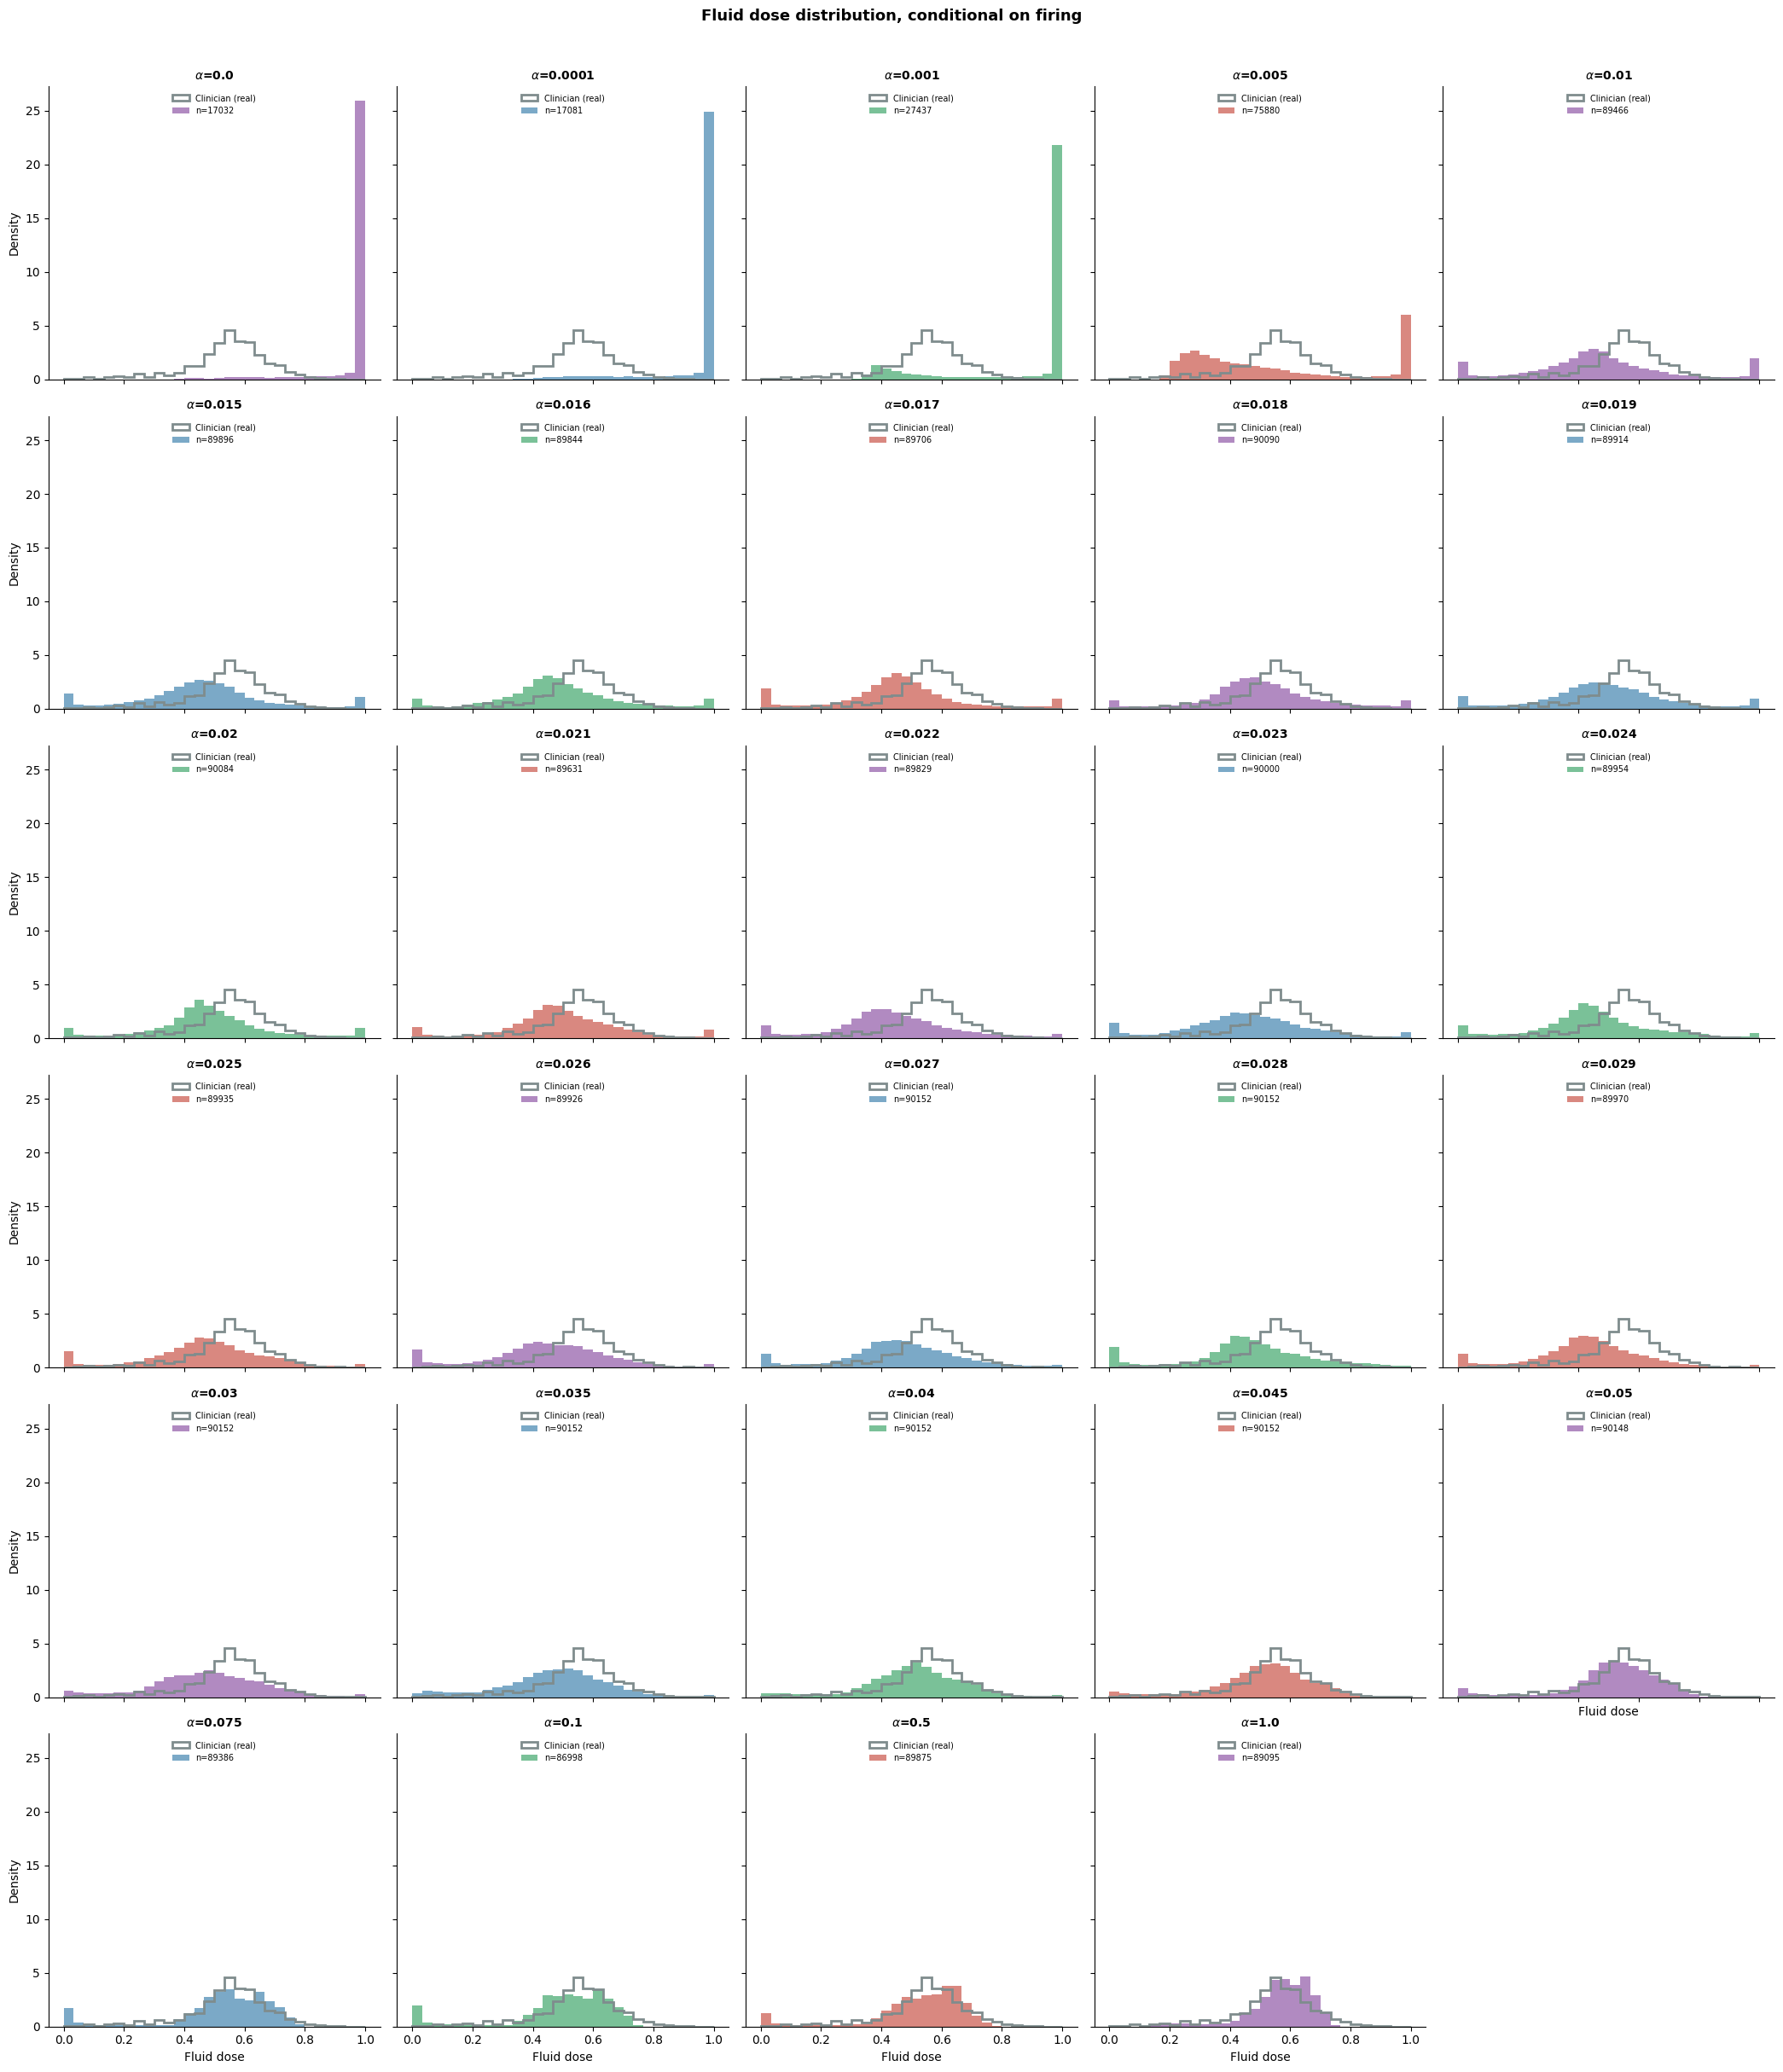

In [23]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.015: n=89896, mean=0.4573, std=0.2157, median=0.4564, p10=0.1819, p25=0.3452, p75=0.5595, p90=0.7190
  alpha=0.016: n=89844, mean=0.4816, std=0.2052, median=0.4686, p10=0.2418, p25=0.3773, p75=0.5799, p90=0.7448
  alpha=0.017: n=89706, mean=0.4528, std=0.2138, median=0.4538, p10=0.1524, p25=0.3613, p75=0.5462, p90=0.7030
  alpha=0.018: n=90090, mean=0.5011, std=0.1961, median=0.4908, p10=0.2901, p25=0.4008, p75=0.5990, p90=0.7480
  alpha=0.019: n=89914, mean=0.4821, std=0.2138, median=0.4784, p10=0.2183, p25=0.3685, p75=0.5984, p90=0.7449
  alpha=0.02: n=90084, mean=0.4828, std=0.1999, median=0.4717, p10=0.2554, p25=0.3928, p75=0.5723, p90=0.7277
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose

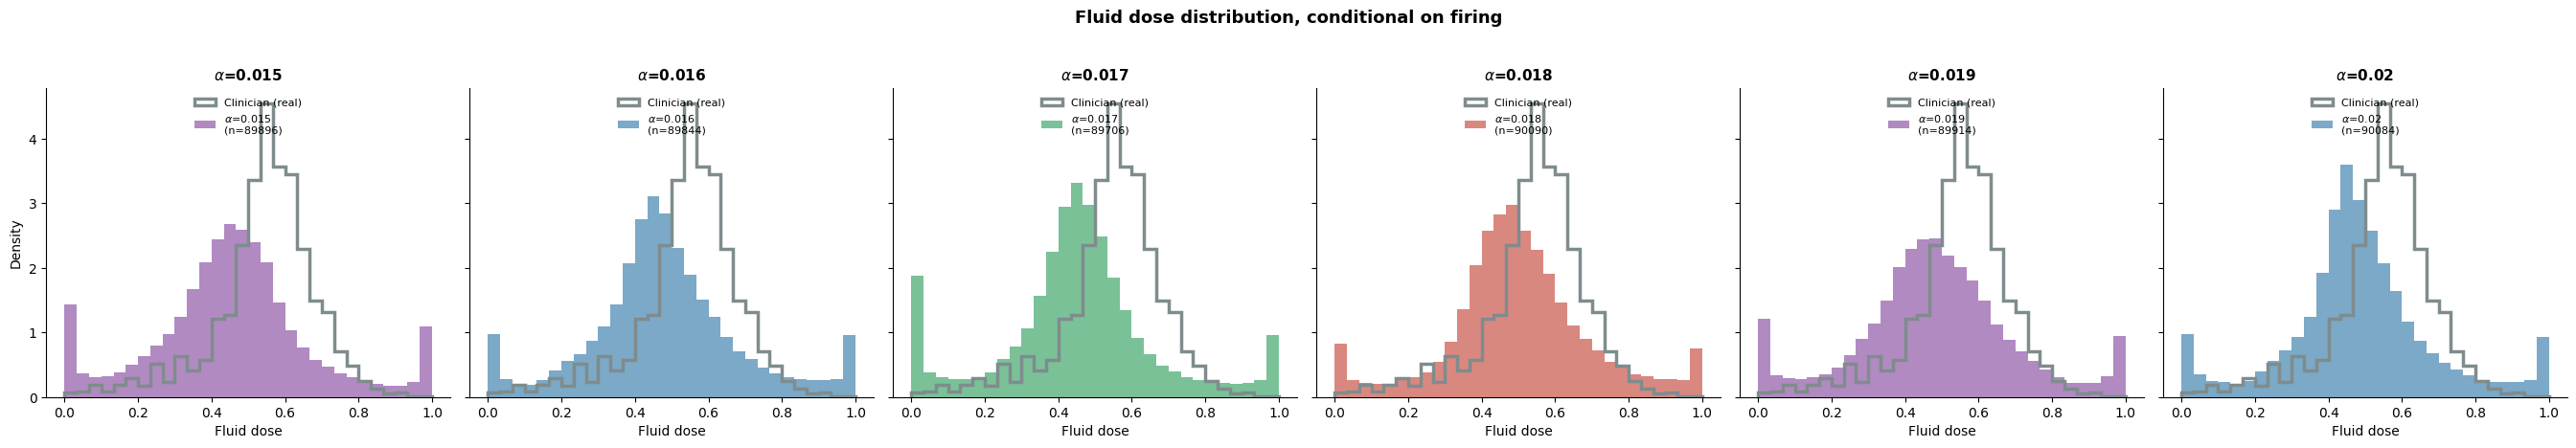

In [22]:
fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.015, 0.016, 0.017, 0.018, 0.019, 0.02],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.0: n=17032, mean=0.9659, std=0.1037, median=1.0000, p10=0.8997, p25=0.9995, p75=1.0000, p90=1.0000
  alpha=0.001: n=27437, mean=0.8842, std=0.2141, median=1.0000, p10=0.4432, p25=0.9246, p75=1.0000, p90=1.0000
  alpha=0.01: n=89466, mean=0.4707, std=0.2382, median=0.4556, p10=0.1625, p25=0.3465, p75=0.5798, p90=0.8170
  alpha=0.025: n=89935, mean=0.4652, std=0.2012, median=0.4737, p10=0.1971, p25=0.3666, p75=0.5832, p90=0.7058
  alpha=0.05: n=90148, mean=0.5086, std=0.1616, median=0.5290, p10=0.3247, p25=0.4508, p75=0.6119, p90=0.6832
  alpha=0.1: n=86998, mean=0.4914, std=0.1791, median=0.5272, p10=0.2045, p25=0.4418, p75=0.6146, p90=0.6656
  alpha=1.0: n=89095, mean=0.5681, std=0.1093, median=0.5844, p10=0.4475, p25=0.5263, p75=0.6439, p90=0.6808
Saved to /home/jake/Documents/AI_Clinician/models/rl_m

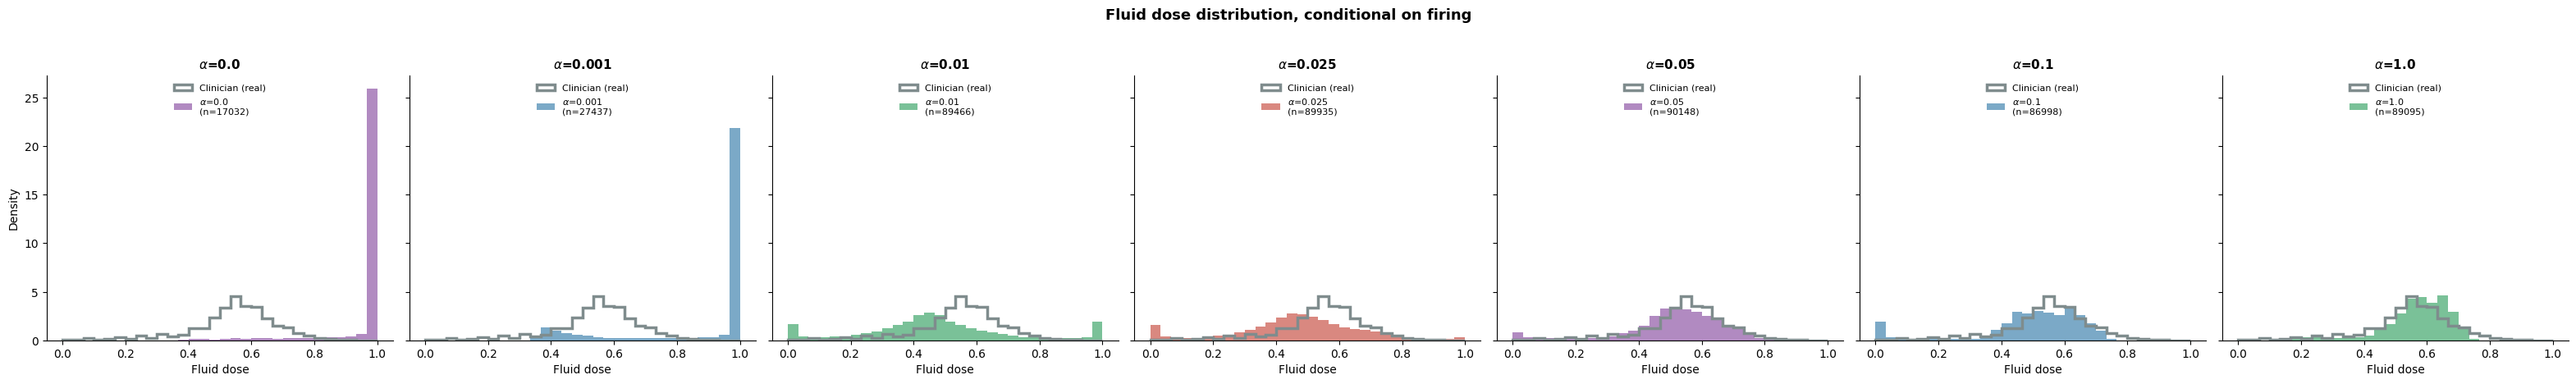

In [20]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.0, 0.001, 0.01, 0.025, 0.05, 0.1, 1.0],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.01: n=89466, mean=0.4707, std=0.2382, median=0.4556, p10=0.1625, p25=0.3465, p75=0.5798, p90=0.8170
  alpha=0.025: n=89935, mean=0.4652, std=0.2012, median=0.4737, p10=0.1971, p25=0.3666, p75=0.5832, p90=0.7058
  alpha=0.05: n=90148, mean=0.5086, std=0.1616, median=0.5290, p10=0.3247, p25=0.4508, p75=0.6119, p90=0.6832
  alpha=0.1: n=86998, mean=0.4914, std=0.1791, median=0.5272, p10=0.2045, p25=0.4418, p75=0.6146, p90=0.6656
  alpha=1.0: n=89095, mean=0.5681, std=0.1093, median=0.5844, p10=0.4475, p25=0.5263, p75=0.6439, p90=0.6808
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_by_alpha.png


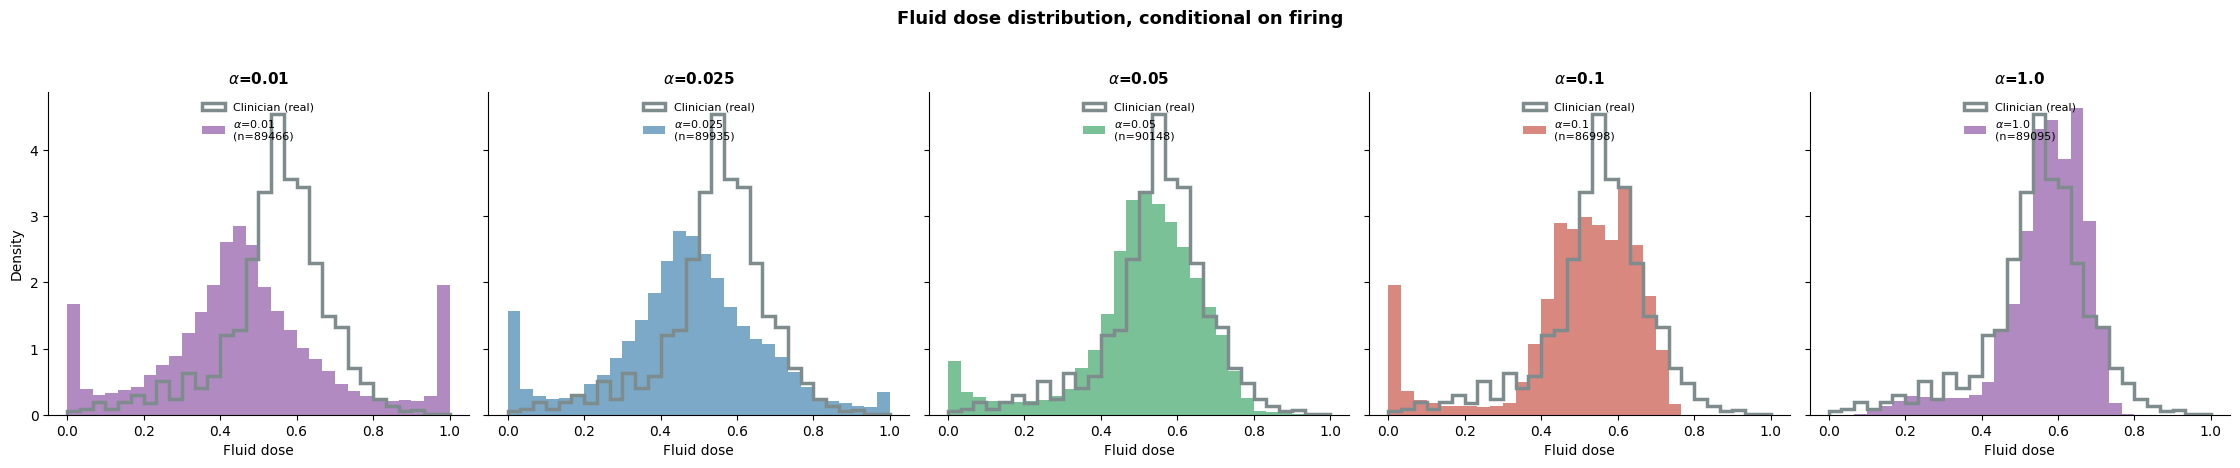

In [21]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.01, 0.025, 0.05, 0.1, 1.0],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== f_raw_mean / f_std summary across alpha ===
  alpha=0.01: f_raw_mean [mean=0.036, std=3.206, min=-12.724, max=30.098, p10=-1.775, p90=1.476]  f_std [mean=0.755, min=0.231, max=2.718]
  alpha=0.025: f_raw_mean [mean=-0.299, std=1.681, min=-12.100, max=21.516, p10=-1.444, p90=0.874]  f_std [mean=0.749, min=0.183, max=2.718]
  alpha=0.05: f_raw_mean [mean=-0.057, std=1.031, min=-9.624, max=4.909, p10=-0.733, p90=0.769]  f_std [mean=0.733, min=0.172, max=2.718]
  alpha=0.1: f_raw_mean [mean=-0.735, std=2.770, min=-20.750, max=1.202, p10=-3.238, p90=0.682]  f_std [mean=0.750, min=0.180, max=2.718]
  alpha=1.0: f_raw_mean [mean=0.260, std=0.504, min=-3.579, max=1.246, p10=-0.236, p90=0.756]  f_std [mean=0.162, min=0.135, max=2.137]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_raw_params_by_alpha.png


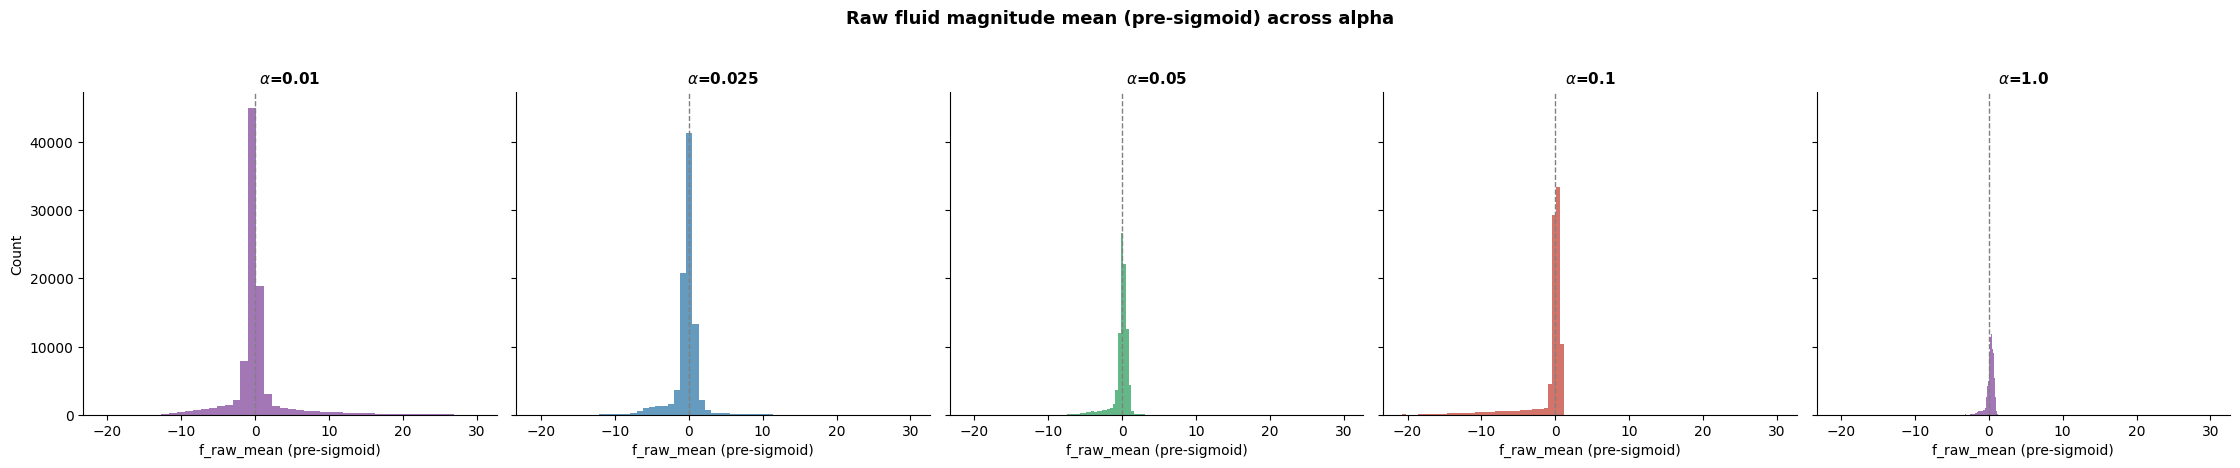

In [24]:
fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.01, 0.025, 0.05, 0.1, 1.0],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

# model fixes to prevent std from reachign floor

In [23]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_113911/local_2726772d
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_113911/local_2726772d/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_113911/local_2726772d, checking parent dire

In [25]:
# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))


Health-score alphas found: [0.006]


=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.006: n=85555, mean=0.5075, std=0.3006, median=0.4751, p10=0.0805, p25=0.3041, p75=0.7042, p90=0.9995
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_by_alpha.png


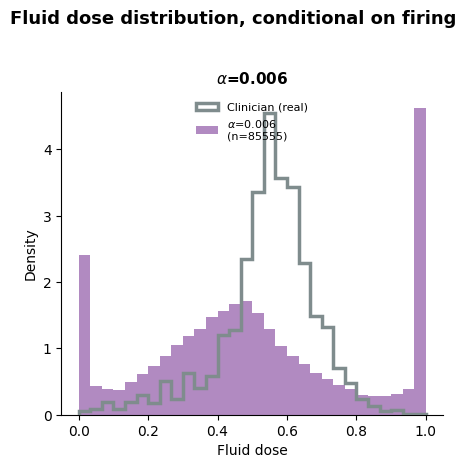

In [28]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== f_raw_mean / f_std summary across alpha ===
  alpha=0.006: f_raw_mean [mean=0.307, std=5.695, min=-21.048, max=24.240, p10=-5.216, p90=7.144]  f_std [mean=0.957, min=0.190, max=2.718]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_raw_params_by_alpha.png


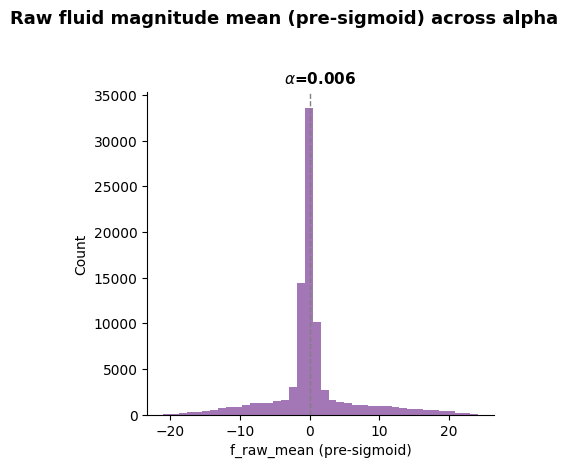

In [27]:
fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix2/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_132727/local_a79ed2a4
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix2/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_132727/local_a79ed2a4/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix2/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_132727/local_a79ed2a4, checking parent d

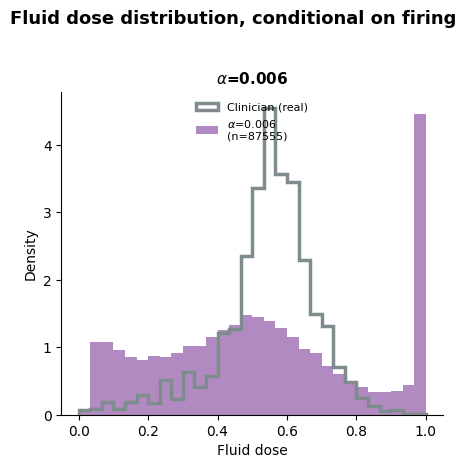

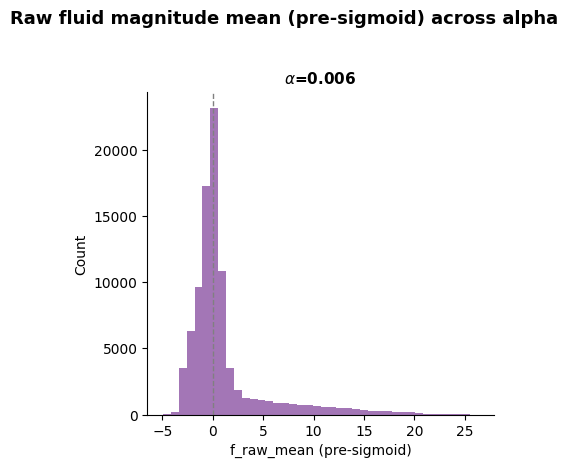

In [14]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix2")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix3/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_144214/local_f6df6372
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix3/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_144214/local_f6df6372/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix3/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_144214/local_f6df6372, checking parent d

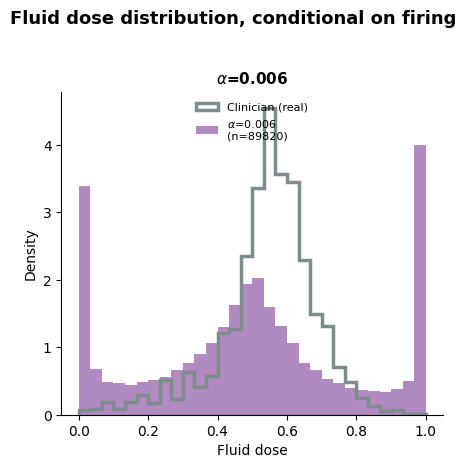

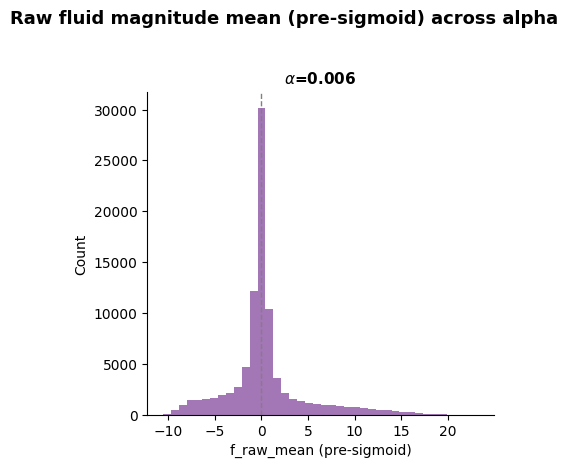

In [16]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix3")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix4/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_155019/local_82fc2edf
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix4/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_155019/local_82fc2edf/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix4/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_155019/local_82fc2edf, checking parent d

RuntimeError: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW

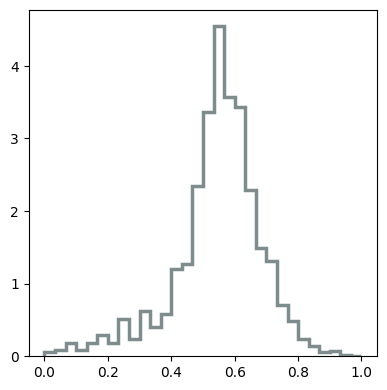

In [14]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix4")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix5/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_182105/unknown_cx3-20-1_20260910-182245_8d420c2e
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix5/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_182105/unknown_cx3-20-1_20260910-182245_8d420c2e/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix5/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_a

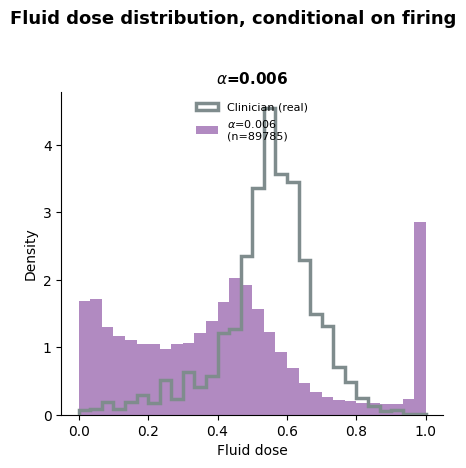

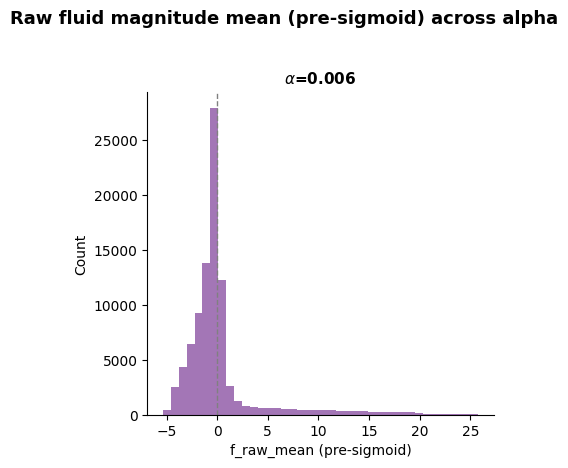

In [15]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix5")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

In [16]:
f_raw_mean, f_p = spike_diag.get_raw_params_and_gate(
    cql_health_score_fixed_alpha_models[0],  # adjust to however you're indexing the single model you loaded
    processors['test'],
)
clinician_actions_test = processors['test'].rl_dataset["actions"]

spike_mask = spike_diag.diagnose_fluid_spike(
    f_raw_mean, f_p, test_health_score, clinician_actions_test,
    spike_threshold=5.0,
)

Spike threshold: f_raw_mean > 5.0
Fraction of states in spike: 0.0678  (7907 of 116662)

--- Health score (severity) ---
  Spike states:     mean=56.91, std=24.49, p10=18.12, p90=81.78
  Non-spike states: mean=78.89, std=14.88, p10=66.17, p90=90.88

--- Gate confidence (f_p) ---
  Spike states:     mean=0.991400, min=0.000000, max=1.000000
  Non-spike states: mean=0.984645, min=0.000000, max=1.000000
  Spike states within 1e-4 of f_p=1.0: 0.9914
  Spike states within 1e-6 of f_p=1.0: 0.9914

--- Real clinician fluid dose, at these same states ---
  Spike states:     mean=0.5683, median=0.5880
  Non-spike states: mean=0.4843, median=0.5455

--- Real clinician VASO dose, at these same states (checking for cross-drug pattern) ---
  Spike states:     mean=0.0959, fire_rate=0.3220
  Non-spike states: mean=0.0209, fire_rate=0.0770


Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_two_population_by_vaso.png


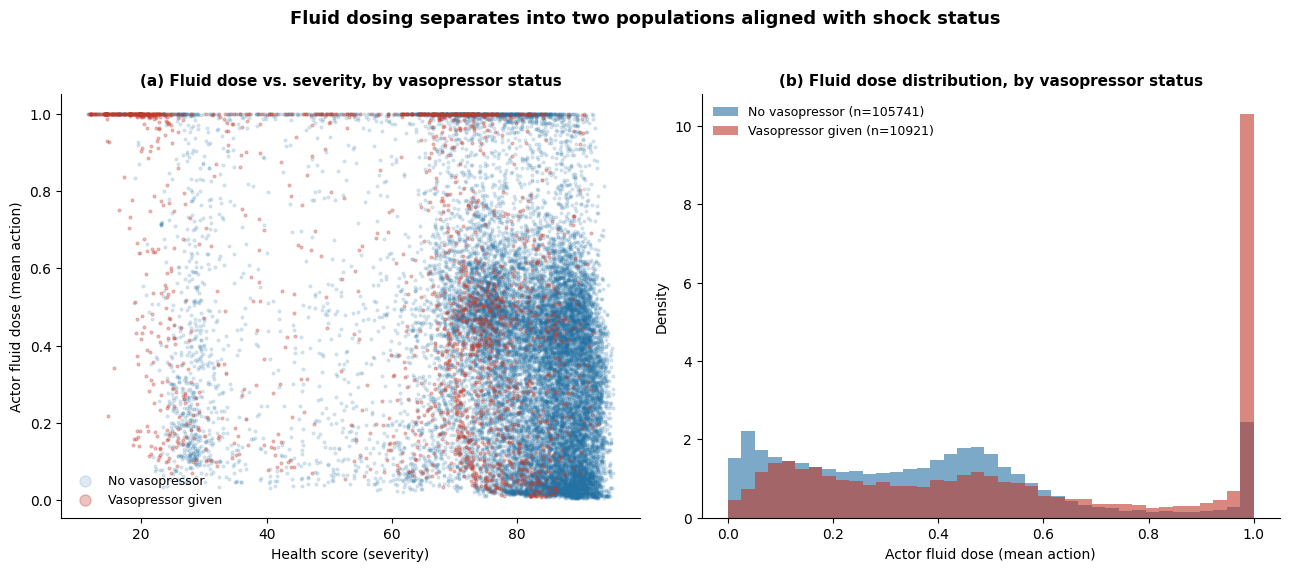

In [17]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
fig = fluid_pop.plot_fluid_spike_by_severity_and_vaso(
    f_raw_mean, test_health_score, clinician_actions_test,
    save_path=os.path.join(cql_model_dir, "fluid_two_population_by_vaso.png"),
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_dose_severity_heatmaps_normalized.png

Fraction of ALL states with dose>0.9: 0.1002
Fraction of states with dose>0.9 that are ALSO (health_score>70 AND no vaso): 0.4329
  (i.e. this fraction of the high-dose spike is NOT explained by sickness+vaso)
For comparison, (health_score>70 AND no vaso) as a fraction of ALL states: 0.7837
  (if the two numbers above are similar, the spike is NOT concentrated away from this group -- i.e. sickness/vaso does NOT explain the spike)


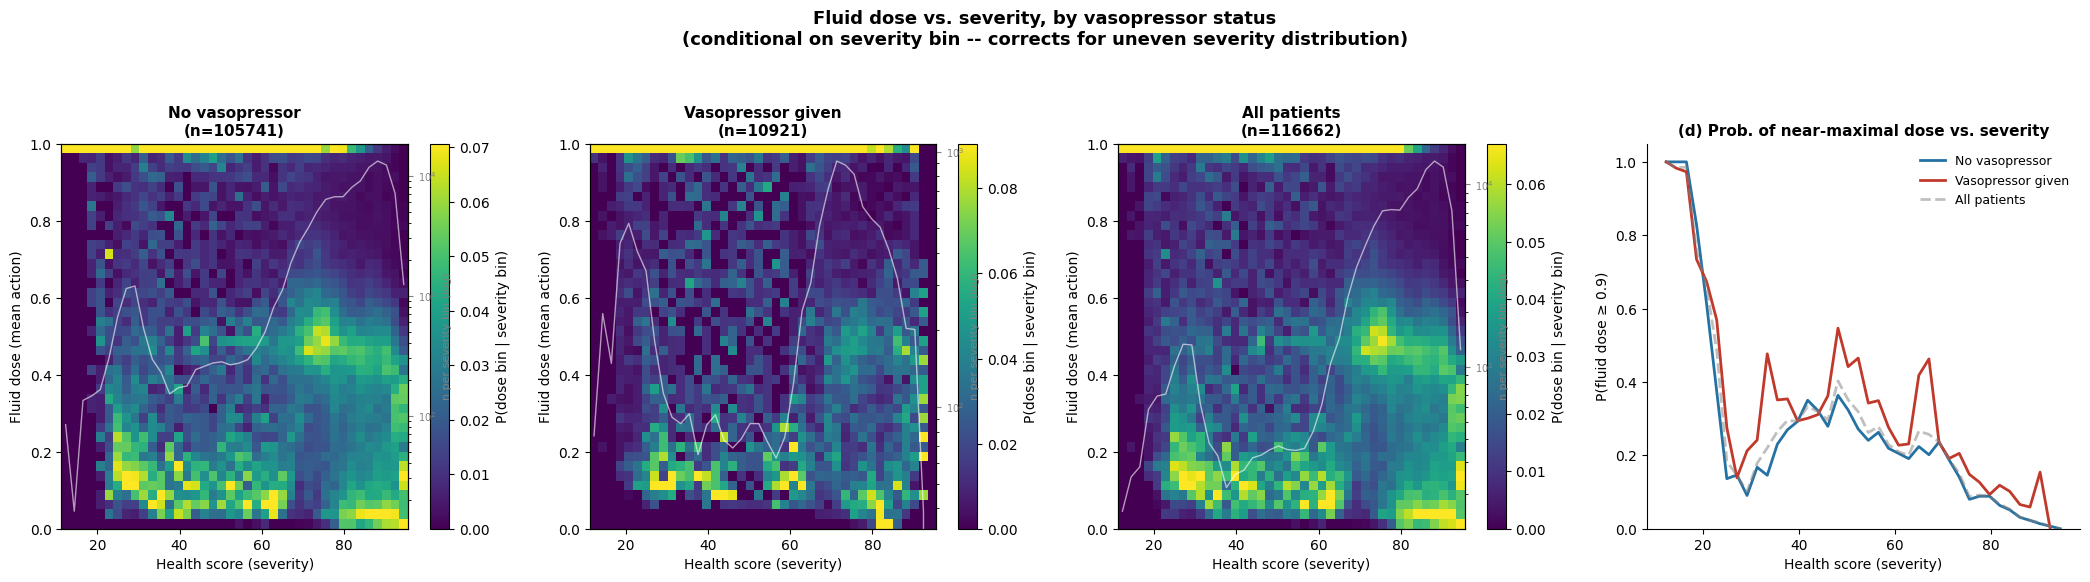

In [19]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
fig = heatmap_diag.plot_fluid_dose_severity_heatmaps(
    f_raw_mean, test_health_score, clinician_actions_test,
    normalize="severity_bin",
    save_path=os.path.join(cql_model_dir, "fluid_dose_severity_heatmaps_normalized.png"),
)

## terminal models

=== alpha=0.0 ===


    own-critic Q IQR (real clinician actions): 3.4619
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2745, normalized=0.0793
  SARSA-critic advantage: raw mean=0.2798, normalized mean=0.0809 (normalized per-seed=[0.0829 0.0929 0.0698 0.0855 0.0736])
  occupancy support of chosen actions: 83.1%
  done in 6.1s

=== alpha=0.0001 ===
    own-critic Q IQR (real clinician actions): 3.4603
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2701, normalized=0.0781
  SARSA-criti

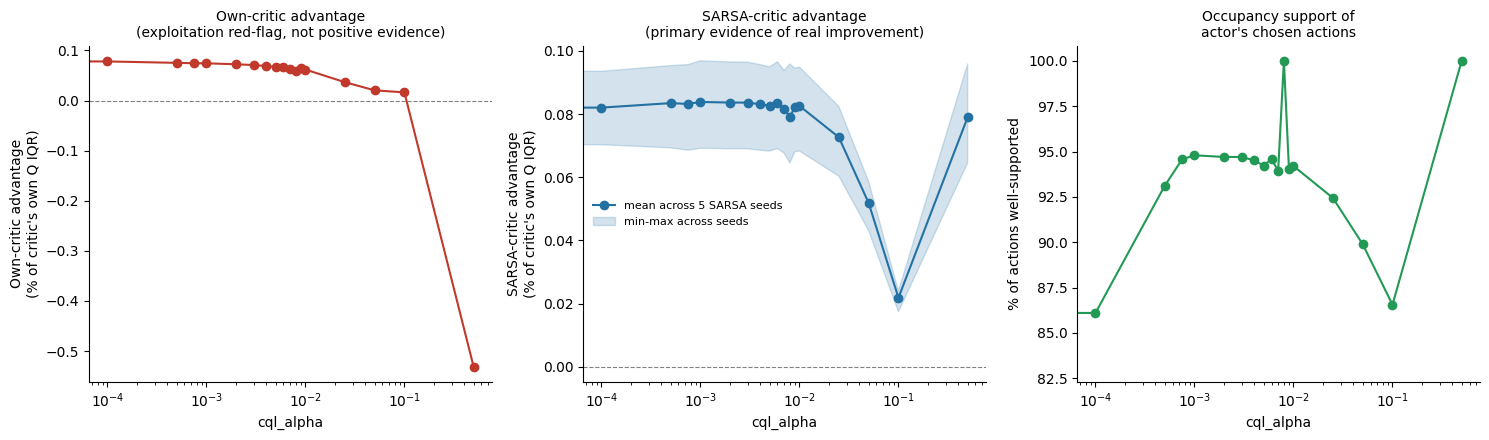

In [38]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_terminal_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_terminal, fig_terminal = eval_cql.run_alpha_sweep_analysis(
    cql_terminal_by_alpha,
    processors['val'],
    basic_q_terminal_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 100,
    save_path=save_path,
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_terminal_n_severity_bins_100.png


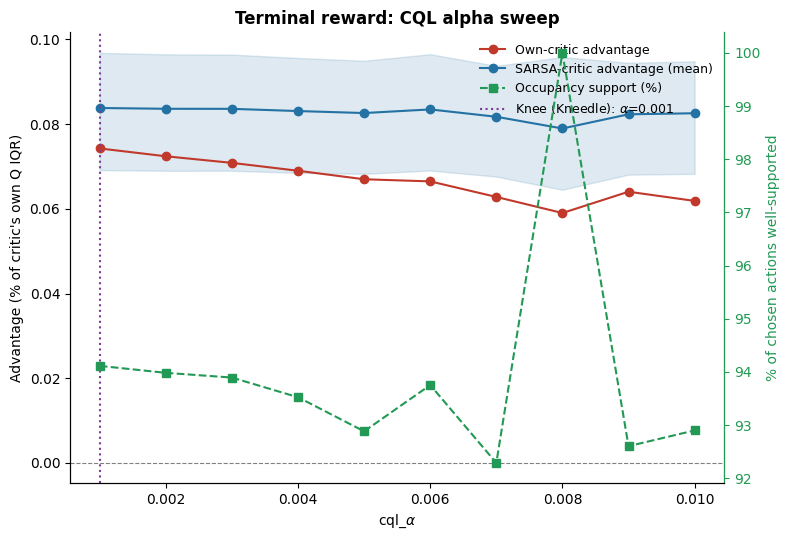

In [17]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_terminal,
    normalized=True,
    title="Terminal reward: CQL alpha sweep",
    save_path=save_path,
)

alpha=0.001: fluid[rate=10.9%, mean=0.1081, nonzero_mean=0.9903]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=12.3%, mean=0.1127, nonzero_mean=0.9183]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=11.4%, mean=0.1139, nonzero_mean=0.9995]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=12.0%, mean=0.1199, nonzero_mean=0.9956]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=13.5%, mean=0.1347, nonzero_mean=0.9957]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=11.8%, mean=0.1178, nonzero_mean=0.9978]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=16.5%, mean=0.1510, nonzero_mean=0.9155]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=0.0%, mean=0.0000, nonzero_mean=nan]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=14.1%, mean=0.1409, nonzero_mean=0.9970]  vaso[rate=0.0%, mean=0.0000, nonze

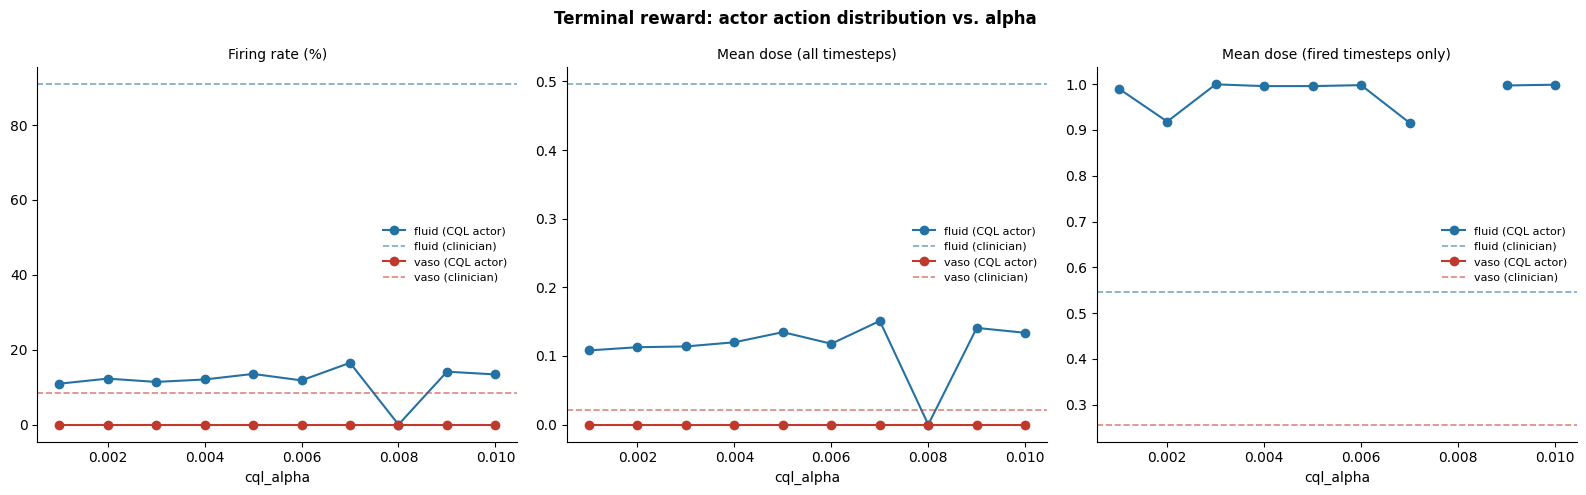

In [31]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])

results_actions_terminal, fig_actions_terminal = action_dist.run_action_distribution_sweep(
    cql_terminal_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Terminal reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_terminal.png"),
)

alpha=0.001: fluid[rate=30.3%, mean=0.2437, nonzero_mean=0.8053]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=56.3%, mean=0.3414, nonzero_mean=0.6069]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=77.5%, mean=0.4594, nonzero_mean=0.5930]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=87.2%, mean=0.4952, nonzero_mean=0.5676]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=94.8%, mean=0.4810, nonzero_mean=0.5077]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=97.2%, mean=0.4264, nonzero_mean=0.4387]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=97.1%, mean=0.4561, nonzero_mean=0.4698]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=99.1%, mean=0.4676, nonzero_mean=0.4717]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=99.8%, mean=0.4724, nonzero_mean=0.4736]  vaso[rate=0.0%, mean=0.0000, n

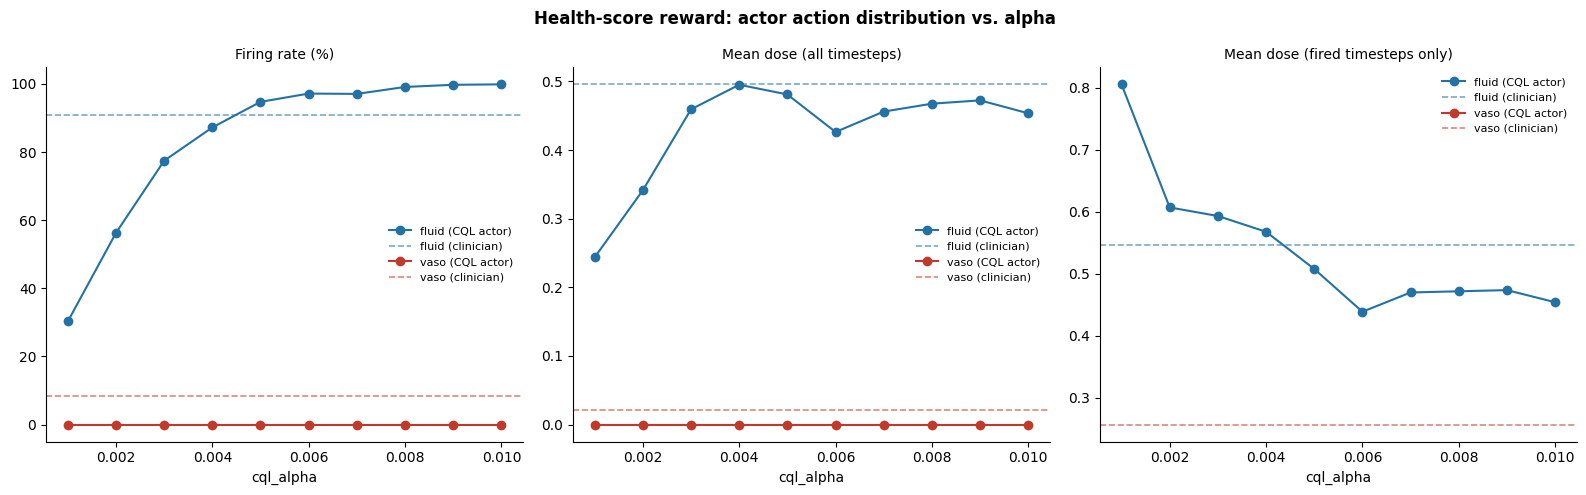

In [32]:
results_actions_health_score, fig_actions_health_score = action_dist.run_action_distribution_sweep(
    cql_health_score_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Health-score reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_health_score.png"),
)

# final 5 seed models with fixed cql alpha

In [20]:
cql_model_dir

'/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset'

In [21]:
cql_terminal_fixed_alpha_model_dir = os.path.join(cql_model_dir, "terminal_only", "fixed_alpha")
cql_terminal_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_terminal_fixed_alpha_model_dir)

cql_terminal_fixed_alpha_models = []
for model_dir in cql_terminal_fixed_alpha_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_fixed_alpha_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-220822_0ce993d0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-223125_f7922617
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-215444_c0ab74de
Found model directory: /home/ja

In [23]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-110857_6a599bed
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-095956_924ca060
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-101849_70f2dd3

seed 1/5: fluid[rate=93.2%, mean=0.4356, nonzero_mean=0.4677]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=93.3%, mean=0.4161, nonzero_mean=0.4458]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=92.5%, mean=0.3793, nonzero_mean=0.4102]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=95.4%, mean=0.3856, nonzero_mean=0.4043]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=98.7%, mean=0.4178, nonzero_mean=0.4234]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_health_score.png


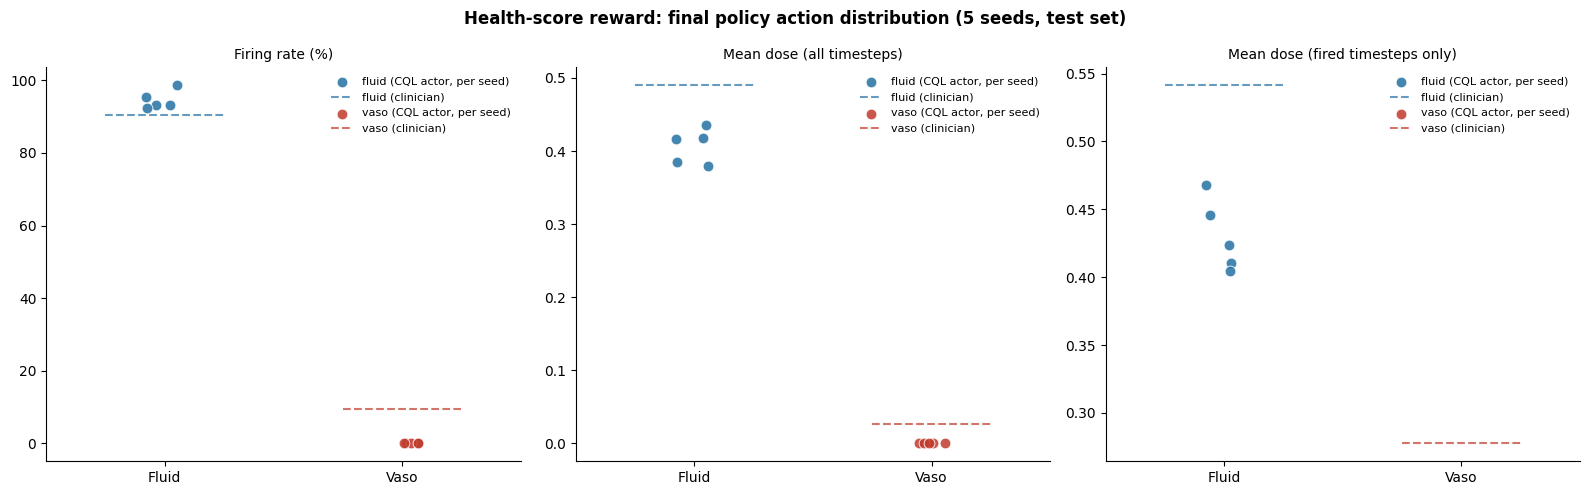

In [24]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])

stats_health_score, fig_health_score = action_dist.run_action_distribution_stage3(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Health-score reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_health_score.png"),
)

In [26]:
all_f_std, all_v_std = std_check.check_std_floor_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['val'],
)

Floor std (exp(log_std_min=-2.0)) = 0.1353
Ceiling std (exp(log_std_max=1.0)) = 2.7183

seed 1: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2166, min=0.1353, max=0.2815, %_at_floor=3.0%]
seed 2: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2014, min=0.1353, max=0.2508, %_at_floor=1.1%]
seed 3: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2637, min=0.1353, max=0.3252, %_at_floor=0.1%]
seed 4: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.1692, min=0.1353, max=0.2318, %_at_floor=23.9%]
seed 5: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2904, min=0.1353, max=0.4013, %_at_floor=0.1%]

Across all 5 seeds combined: f_std mean=0.1353 (100.0% at floor), v_std mean=0.2283 (5.6% at floor)


seed 1/5: fluid[rate=19.9%, mean=0.1784, nonzero_mean=0.8979]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=15.6%, mean=0.1441, nonzero_mean=0.9243]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=13.8%, mean=0.1362, nonzero_mean=0.9902]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=15.0%, mean=0.1409, nonzero_mean=0.9381]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=12.0%, mean=0.1153, nonzero_mean=0.9619]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_terminal.png


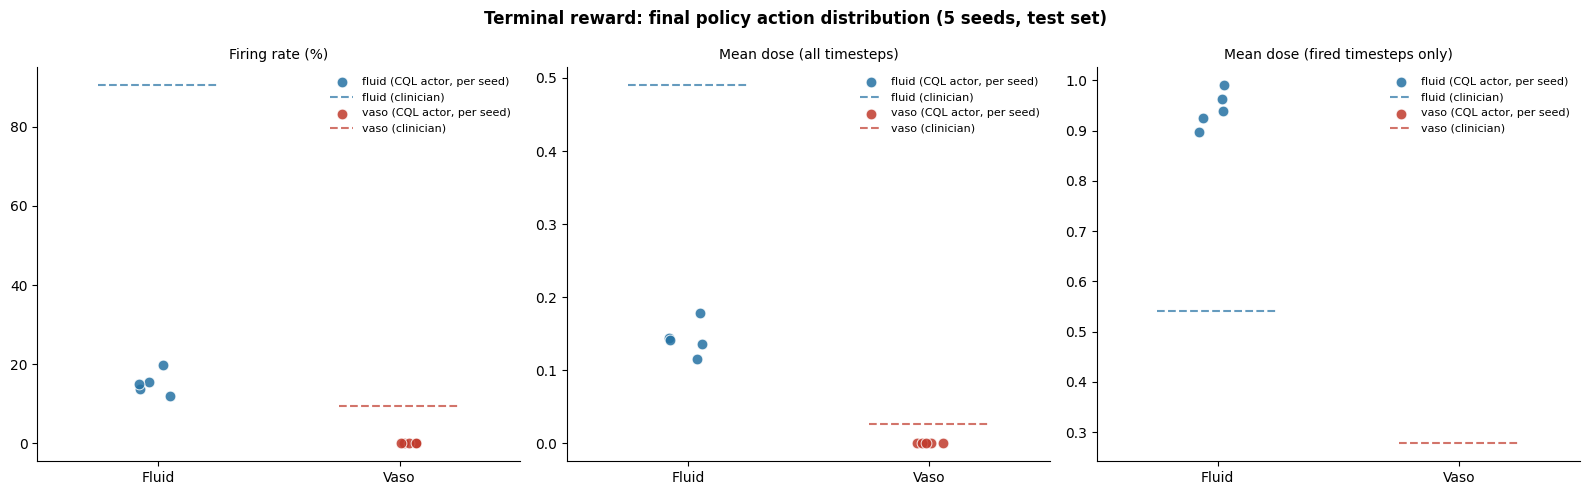

In [39]:
stats_terminal, fig_terminal = action_dist.run_action_distribution_stage3(
    cql_terminal_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Terminal reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_terminal.png"),
)

# reward by vaso 

Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): 0.0440
Total vaso-given timesteps contributing to estimate: 10921
  bin center hs=34.0: vaso mean=0.000447 (n=3660), no_vaso mean=0.095069 (n=8007)
  bin center hs=68.1: vaso mean=0.013176 (n=2498), no_vaso mean=0.016489 (n=9168)
  bin center hs=73.9: vaso mean=0.078589 (n=1616), no_vaso mean=0.082335 (n=10050)
  bin center hs=77.5: vaso mean=-0.013044 (n=1041), no_vaso mean=0.044067 (n=10625)
  bin center hs=80.8: vaso mean=0.041779 (n=793), no_vaso mean=0.066261 (n=10873)
  bin center hs=83.7: vaso mean=0.063762 (n=539), no_vaso mean=0.047470 (n=11127)
  bin center hs=86.1: vaso mean=-0.134604 (n=326), no_vaso mean=0.029251 (n=11340)
  bin center hs=88.0: vaso mean=-0.038649 (n=172), no_vaso mean=-0.012884 (n=11494)
  bin center hs=89.8: vaso mean=-0.004516 (n=203), no_vaso mean=-0.023176 (n=11463)
  bin center hs=92.1: vaso mean=0.015111 (n=73), no_vaso mean=-0.037300 (n=11594)
Saved to /home/jake/Documents/AI

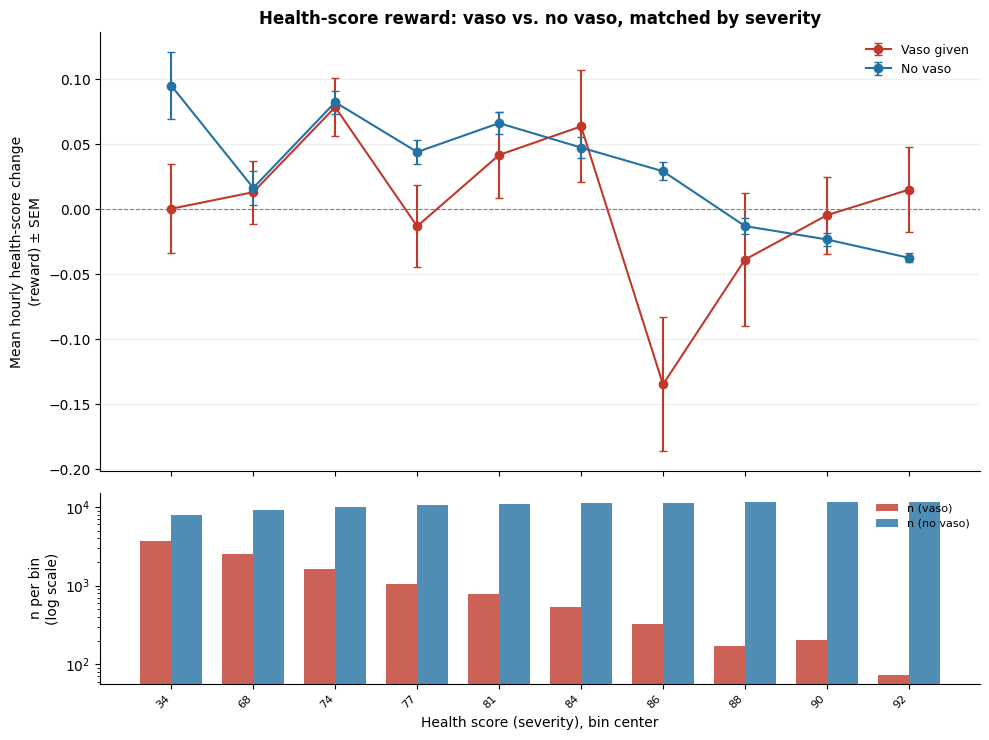

In [65]:
test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

rewards = processors['test'].rl_dataset["rewards"]
actions = processors['test'].rl_dataset["actions"]

health_score = processors['test'].dynamic_deephit_predictions['health_score'] 

results = vaso_match.compare_reward_by_vaso(
    rewards, actions, test_health_score, n_severity_bins=10
)

effect, total_n_vaso = vaso_match.matched_effect_estimate(results)
print(f"Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): {effect:.4f}")
print(f"Total vaso-given timesteps contributing to estimate: {total_n_vaso}")

for b in range(len(results["bin_center_health_score"])):
    print(f"  bin center hs={results['bin_center_health_score'][b]:.1f}: "
      f"vaso mean={results['mean_reward_vaso'][b]:.6f} (n={results['n_vaso'][b]}), "
      f"no_vaso mean={results['mean_reward_no_vaso'][b]:.6f} (n={results['n_no_vaso'][b]})")

fig = vaso_match.plot_reward_by_vaso(
    results,
    title="Health-score reward: vaso vs. no vaso, matched by severity",
    save_path=os.path.join(cql_model_dir, "reward_by_vaso_matched.png"),
)

In [1]:
val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

rewards = processors['val'].rl_dataset["rewards"]
actions = processors['val'].rl_dataset["actions"]

health_score = processors['val'].dynamic_deephit_predictions['health_score'] 

results = vaso_match.compare_reward_by_vaso(
    rewards, actions, val_health_score, n_severity_bins=10
)

effect, total_n_vaso = vaso_match.matched_effect_estimate(results)
print(f"Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): {effect:.4f}")
print(f"Total vaso-given timesteps contributing to estimate: {total_n_vaso}")

for b in range(len(results["bin_center_health_score"])):
    print(f"  bin center hs={results['bin_center_health_score'][b]:.1f}: "
      f"vaso mean={results['mean_reward_vaso'][b]:.6f} (n={results['n_vaso'][b]}), "
      f"no_vaso mean={results['mean_reward_no_vaso'][b]:.6f} (n={results['n_no_vaso'][b]})")

fig = vaso_match.plot_reward_by_vaso(
    results,
    title="Health-score reward: vaso vs. no vaso, matched by severity",
    save_path=os.path.join(cql_model_dir, "reward_by_vaso_matched_VALIDATION.png"),
)

NameError: name 'processors' is not defined